# KNN(K-Nearest Neighbor)

[Contents]
1. KNN Low-level implementation  
2. KNN Classification   
   2-1) k에 따른 성과 비교  
   2-2) Scaling 영향 비교

[Data]  
Wine recognition Data set (Multi Class)  
https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-dataset  
shape : 178*13
  
[Task]
1. 최적의 K값 탐색 등 KNN을 활용하여 예측성능 확보하기

활용 데이터
 - Breast Cancer Wisconsin (Diagnostic)
 - https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

[Note]


### KNN Low-level implementation  
 - 관련 Library없이 numpy를 활용한 저수준 구현

In [ ]:
import numpy as np
from collections import Counter

class KNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def predict(self, X):
        preds = [self._predict_one(x) for x in X]
        return np.array(preds)

    def _predict_one(self, x):
        # 거리 계산 (유클리드 거리)
        distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))

        # k개의 최근접 이웃 선택
        k_indices = distances.argsort()[:self.k]
        k_neighbor_labels = self.y_train[k_indices]

        # 다수결 투표
        most_common = Counter(k_neighbor_labels).most_common(1)
        return most_common[0][0]

# 예시 데이터 (이진 분류)
X_train = [[1,2],[2,3],[3,3],[6,7],[7,8],[8,8]]
y_train = [0,0,0,1,1,1]

knn = KNN(k=3)
knn.fit(X_train, y_train)

X_test = [[2,2],[7,7],[3,7]]
print("KNN Inference:", knn.predict(X_test))

KNN Inference: [0 1 0]


### KNN Classification  

- KNN은 거리 기반 알고리즘이므로 특성 스케일링이 중요  
- K값이 너무 작으면 과적합, 너무 크면 과소적합 경향  
- 홀수 K값 사용권고, 동점 상황 방지  

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
# 1. 데이터 로드
wine = load_wine()
X, y = wine.data, wine.target

df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y

print(f"Data Shape: {df.shape}")
print(f"Info: {df.info()}")
print(f"Samples: {df.head(5)}")

Data Shape: (178, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

In [4]:
# 2. 데이터 탐색
print("\n결측치 확인:")
print(df.isnull().sum())

print("\n타겟 변수 분포:")
print(f"Target Class Name: {wine.target_names}")
target_counts = df['target'].value_counts()
print(target_counts)
print(f"비율: {target_counts / len(df) * 100}")



결측치 확인:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

타겟 변수 분포:
Target Class Name: ['class_0' 'class_1' 'class_2']
target
1    71
0    59
2    48
Name: count, dtype: int64
비율: target
1    39.887640
0    33.146067
2    26.966292
Name: count, dtype: float64


In [5]:
# 3. 모델링
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3-1 K값 비교 (스케일링 전)
k_values = [1, 3, 5, 9, 11]
accuracies_no_scaling = []

print("\n=== 스케일링 전 결과 ===")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies_no_scaling.append(accuracy)
    print(f"K={k}: Accuracy = {accuracy:.4f}")

# 3-2 스케일링 적용
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3-3 K값 비교 (스케일링 후)
accuracies_with_scaling = []

print("\n=== 스케일링 후 결과 ===")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies_with_scaling.append(accuracy)
    print(f"K={k}: Accuracy = {accuracy:.4f}")

# 3-4 최적 모델 선택 및 상세 평가
best_k_idx = np.argmax(accuracies_with_scaling)
best_k = k_values[best_k_idx]
print(f"\n최적 K값: {best_k} (Accuracy: {accuracies_with_scaling[best_k_idx]:.4f})")

# 3-5 최적 모델로 예측
best_knn = KNeighborsClassifier(
    n_neighbors=best_k
   #  ,metric     # 'minkowski'(Default), 'euclidean', 'manhattan', 'cosine', 'mahalanobis'..
   #  ,p          # Minkowski 거리의 차수, p=1: manhattan, p=2: euclidean(Default)
   #  ,weights    # 'uniform': 모든 이웃이 동일한 가중치(Default), 'distance': 가까운 이웃에 더 큰 가중치
    )
best_knn.fit(X_train_scaled, y_train)
y_pred_best = best_knn.predict(X_test_scaled)


=== 스케일링 전 결과 ===
K=1: Accuracy = 0.7778
K=3: Accuracy = 0.7500
K=5: Accuracy = 0.8056
K=9: Accuracy = 0.8056
K=11: Accuracy = 0.8056

=== 스케일링 후 결과 ===
K=1: Accuracy = 0.9722
K=3: Accuracy = 0.9722
K=5: Accuracy = 0.9722
K=9: Accuracy = 1.0000
K=11: Accuracy = 1.0000

최적 K값: 9 (Accuracy: 1.0000)


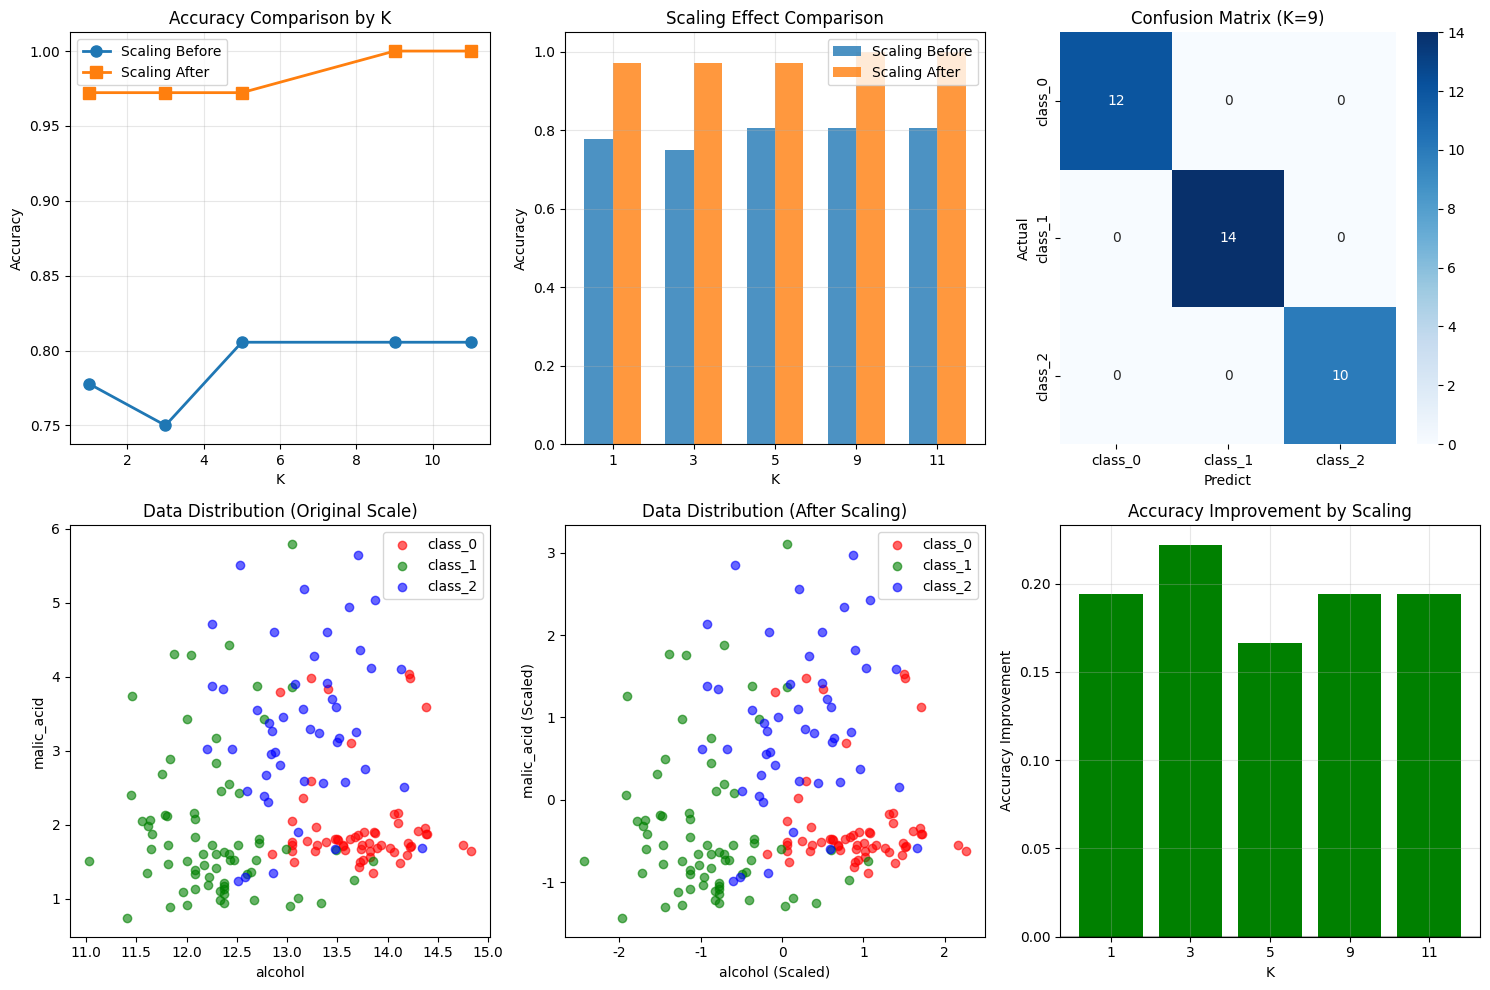


=== 최종 결과 요약 ===
최적 K값: 9
최종 정확도: 1.0000
스케일링 효과: 0.1944

=== 상세 분류 보고서 ===
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

이 데이터셋에서는 스케일링 후 평균 0.1944 정확도 향상


In [ ]:
# 4. 성과분석
plt.figure(figsize=(15, 10))

# 4-1. K값에 따른 정확도 비교
plt.subplot(2, 3, 1)
plt.plot(k_values, accuracies_no_scaling, 'o-', label='Scaling Before', linewidth=2, markersize=8)
plt.plot(k_values, accuracies_with_scaling, 's-', label='Scaling After', linewidth=2, markersize=8)
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Accuracy Comparison by K')
plt.legend()
plt.grid(True, alpha=0.3)

# 4-2. 스케일링 효과 막대 그래프
plt.subplot(2, 3, 2)
x_pos = np.arange(len(k_values))
width = 0.35
plt.bar(x_pos - width/2, accuracies_no_scaling, width, label='Scaling Before', alpha=0.8)
plt.bar(x_pos + width/2, accuracies_with_scaling, width, label='Scaling After', alpha=0.8)
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Scaling Effect Comparison')
plt.xticks(x_pos, k_values)
plt.legend()
plt.grid(True, alpha=0.3)

# 4-3. 혼동 행렬
plt.subplot(2, 3, 3)
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title(f'Confusion Matrix (K={best_k})')
plt.ylabel('Actual')
plt.xlabel('Predict')

# 4-4. 특성 분포 (처음 2개 특성만)
plt.subplot(2, 3, 4)
colors = ['red', 'green', 'blue']
for i, target_name in enumerate(wine.target_names):
    mask = y == i
    plt.scatter(X[mask, 0], X[mask, 1], c=colors[i], label=target_name, alpha=0.6)
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.title('Data Distribution (Original Scale)')
plt.legend()

# 4-5. 스케일링된 특성 분포
plt.subplot(2, 3, 5)
X_all_scaled = scaler.fit_transform(X)
for i, target_name in enumerate(wine.target_names):
    mask = y == i
    plt.scatter(X_all_scaled[mask, 0], X_all_scaled[mask, 1], c=colors[i], label=target_name, alpha=0.6)
plt.xlabel(f'{wine.feature_names[0]} (Scaled)')
plt.ylabel(f'{wine.feature_names[1]} (Scaled)')
plt.title('Data Distribution (After Scaling)')
plt.legend()

# 4-6. 정확도 향상 비교
plt.subplot(2, 3, 6)
improvement = np.array(accuracies_with_scaling) - np.array(accuracies_no_scaling)
plt.bar(range(len(k_values)), improvement, color=['green' if x > 0 else 'red' for x in improvement])
plt.xlabel('K')
plt.ylabel('Accuracy Improvement')
plt.title('Accuracy Improvement by Scaling')
plt.xticks(range(len(k_values)), k_values)
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. 최종 결과 요약
print(f"\n=== 최종 결과 요약 ===")
print(f"최적 K값: {best_k}")
print(f"최종 정확도: {accuracies_with_scaling[best_k_idx]:.4f}")
print(f"스케일링 효과: {accuracies_with_scaling[best_k_idx] - accuracies_no_scaling[best_k_idx]:.4f}")

print(f"\n=== 상세 분류 보고서 ===")
print(classification_report(y_test, y_pred_best, target_names=wine.target_names))

print(f"이 데이터셋에서는 스케일링 후 평균 {np.mean(improvement):.4f} 정확도 향상")

### Task: KNN Classification, 최적의 k 탐색으로 변별력 확보하기  


In [6]:
!pip install ucimlrepo

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo

# 1. UCI에서 데이터 불러오기
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# 2. 라벨 인코딩 (M=1, B=0)
le = LabelEncoder()
y = le.fit_transform(y)

# 3. Train/Test 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


---

## Step 0. 평가 프로토콜 고정

**원칙: 모든 탐색은 Train(455건) 내부 CV 로만 한다. Test(114건)는 Step 6 에서 최종 1회만 연다.**

위 예제(cell 7)는 `best_k` 를 **Test Accuracy 로** 골랐다.
Test 를 보고 고른 k 의 Test 성능은 더 이상 일반화 성능이 아니다.
실습1 리포트의 *"Validation 을 보고 골랐으므로 Validation 도 오염된다"* 와 같은 구조의 오류다.

또한 스케일러는 **반드시 `Pipeline` 안에** 넣는다.
CV 바깥에서 `fit_transform` 하면 fold 마다 Test fold 의 평균/분산이 새어 들어간다.

In [2]:
# ============================================================
# Step 0. 공통 설정
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (cross_val_score, GridSearchCV,
                                     RepeatedStratifiedKFold)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score)

RS = 42

# 5-fold x 10 repeat. 평균만 보면 안 되고 표준편차까지 봐야
# "차이"와 "노이즈"를 구분할 수 있다.
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RS)
N_FOLDS = CV.get_n_splits()

def knn_pipe(scaler=None, **knn_kw):
    """스케일러를 Pipeline 안에 넣어 CV leak 을 원천 차단."""
    steps = []
    if scaler is not None:
        steps.append(("scaler", scaler))
    steps.append(("knn", KNeighborsClassifier(**knn_kw)))
    return Pipeline(steps)

def cv_eval(model, X=None, y=None):
    """(평균, 표준편차) 반환."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    s = cross_val_score(model, X, y, cv=CV, scoring="accuracy", n_jobs=-1)
    return s.mean(), s.std()

print(f"Train {X_train.shape}   Test {X_test.shape}")
print(f"Train  B(0)={int((y_train==0).sum())}  M(1)={int((y_train==1).sum())}")
print(f"Test   B(0)={int((y_test==0).sum())}  M(1)={int((y_test==1).sum())}")

BASE_RATE = max((y_test == 0).mean(), (y_test == 1).mean())
print(f"\n[진짜 Baseline] 전부 다수클래스(B)로 찍기 = {BASE_RATE:.4f}")
print("  -> 교재 p.30: 클래스 분포가 불균형하면 다수 투표가 지배한다.")
print("     이 값을 못 넘으면 모델은 아무 의미가 없다.")

Train (455, 30)   Test (114, 30)
Train  B(0)=285  M(1)=170
Test   B(0)=72  M(1)=42

[진짜 Baseline] 전부 다수클래스(B)로 찍기 = 0.6316
  -> 교재 p.30: 클래스 분포가 불균형하면 다수 투표가 지배한다.
     이 값을 못 넘으면 모델은 아무 의미가 없다.


---

## Step 1. 스케일링은 왜 필수인가 — 말이 아니라 숫자로

교재 p.30 Cons: *"모두 수치형 컬럼이라 하더라도 정규화 되어 있지 않거나 (…) 성능은 매우 떨어짐.
Why? Distance를 기준으로 추론하기 때문"*

이 문장을 **거리 기여도**로 정량화한다.
제곱 유클리드 거리 `Σ(xi-yi)²` 에서 각 변수가 차지하는 몫은 그 변수의 **분산 비중**에 비례한다.

In [3]:
# ============================================================
# Step 1-1. 원척도에서 각 변수가 거리에 기여하는 비중
# ============================================================
var = X_train.var(axis=0, ddof=0)
share = (var / var.sum()).sort_values(ascending=False)

print("=== 원척도 제곱 유클리드 거리 기여도 ===")
for name, s in share.head(5).items():
    print(f"  {name:26s} {s*100:6.2f}%")
print(f"  {'-'*34}")
print(f"  {'상위 3개 합계':26s} {share.head(3).sum()*100:6.2f}%")
print(f"  {'하위 27개 합계':26s} {share.tail(27).sum()*100:6.2f}%")

print("\n[해석] 30개 변수를 넣었다고 생각하지만, 실제로는 area 계열 3개로 이웃을 찾고 있다.")
print("       나머지 27개 변수가 나눠 갖는 몫이 채 1%가 안 된다.")
print("       표준화하면 모든 변수의 분산이 1이 되어 30개가 균등하게 1/30씩 기여한다.")

=== 원척도 제곱 유클리드 거리 기여도 ===
  area3                       71.66%
  area1                       27.45%
  area2                        0.49%
  perimeter3                   0.25%
  perimeter1                   0.13%
  ----------------------------------
  상위 3개 합계                    99.60%
  하위 27개 합계                    0.40%

[해석] 30개 변수를 넣었다고 생각하지만, 실제로는 area 계열 3개로 이웃을 찾고 있다.
       나머지 27개 변수가 나눠 갖는 몫이 채 1%가 안 된다.
       표준화하면 모든 변수의 분산이 1이 되어 30개가 균등하게 1/30씩 기여한다.


In [4]:
# ============================================================
# Step 1-2. 원척도 vs 표준화 — CV 로 비교
# ============================================================
KS_QUICK = [1, 3, 5, 9, 11]
raw_m, raw_s, std_m, std_s = [], [], [], []

print("=== 5-fold x 10 repeat CV (Train 455건 내부) ===")
print(f"{'k':>4} | {'원척도':>16} | {'표준화':>16} | {'차이':>7}")
print("-" * 56)
for k in KS_QUICK:
    m1, s1 = cv_eval(knn_pipe(None, n_neighbors=k))
    m2, s2 = cv_eval(knn_pipe(StandardScaler(), n_neighbors=k))
    raw_m.append(m1); raw_s.append(s1)
    std_m.append(m2); std_s.append(s2)
    print(f"{k:>4} | {m1:.4f} +/- {s1:.4f} | {m2:.4f} +/- {s2:.4f} | {m2-m1:+.4f}")

print(f"\n평균 향상: {np.mean(np.array(std_m) - np.array(raw_m)):+.4f}")

=== 5-fold x 10 repeat CV (Train 455건 내부) ===
   k |              원척도 |              표준화 |      차이
--------------------------------------------------------


   1 | 0.9237 +/- 0.0270 | 0.9519 +/- 0.0212 | +0.0281
   3 | 0.9235 +/- 0.0237 | 0.9684 +/- 0.0206 | +0.0448


   5 | 0.9288 +/- 0.0285 | 0.9635 +/- 0.0209 | +0.0347
   9 | 0.9264 +/- 0.0243 | 0.9635 +/- 0.0197 | +0.0371


  11 | 0.9246 +/- 0.0246 | 0.9613 +/- 0.0205 | +0.0367

평균 향상: +0.0363


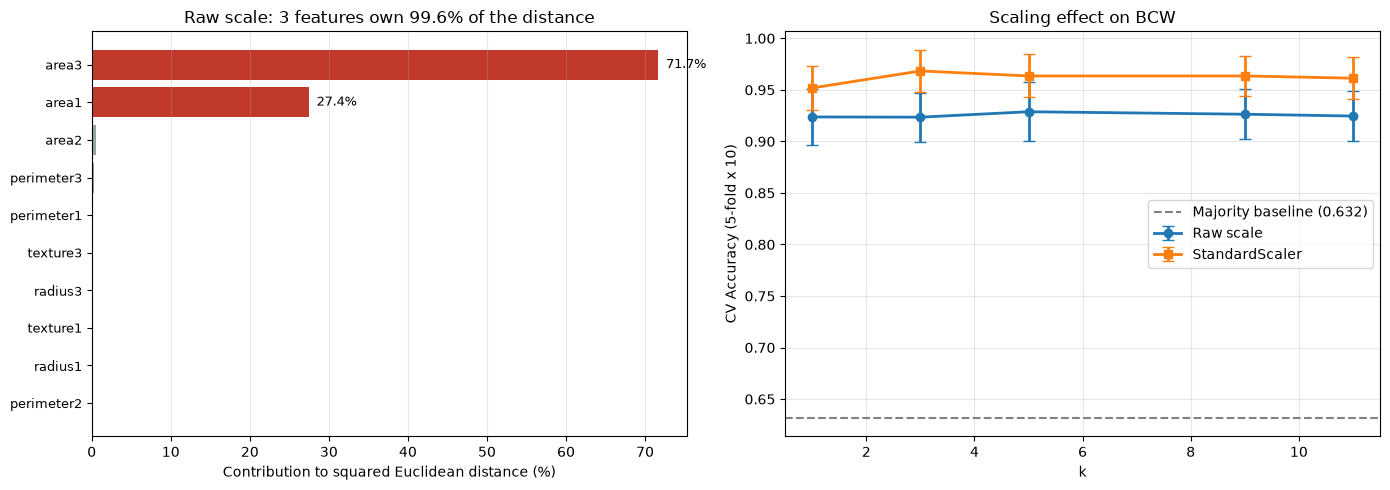

In [5]:
# ============================================================
# [그림 1] 스케일링 효과
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

top10 = share.head(10)[::-1]
colors = ["#c0392b" if v > 0.05 else "#95a5a6" for v in top10]
ax[0].barh(range(len(top10)), top10.values * 100, color=colors)
ax[0].set_yticks(range(len(top10)))
ax[0].set_yticklabels([n[:22] for n in top10.index], fontsize=9)
ax[0].set_xlabel("Contribution to squared Euclidean distance (%)")
ax[0].set_title("Raw scale: 3 features own 99.6% of the distance")
for i, v in enumerate(top10.values * 100):
    if v > 1:
        ax[0].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
ax[0].grid(axis="x", alpha=0.3)

ax[1].errorbar(KS_QUICK, raw_m, yerr=raw_s, fmt="o-", capsize=4,
               label="Raw scale", linewidth=2)
ax[1].errorbar(KS_QUICK, std_m, yerr=std_s, fmt="s-", capsize=4,
               label="StandardScaler", linewidth=2)
ax[1].axhline(BASE_RATE, ls="--", c="gray", label=f"Majority baseline ({BASE_RATE:.3f})")
ax[1].set_xlabel("k"); ax[1].set_ylabel("CV Accuracy (5-fold x 10)")
ax[1].set_title("Scaling effect on BCW")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("knn_fig1_scaling.png", dpi=120, bbox_inches="tight")
plt.show()

### Step 1 해석

Wine 예제(cell 7)에서는 스케일링 효과가 **+0.19** 였는데 BCW 는 **+0.036** 이다.
같은 "스케일링이 중요하다" 인데 왜 이렇게 다른가?

- Wine: `proline`(수백~1500)이 거리를 지배하는데 이 변수만으로는 3개 품종이 안 갈린다 → 원척도가 **망가진다**
- BCW: 거리를 지배하는 `area3`(worst area) 가 **마침 악성/양성을 잘 가르는 변수**다 → 원척도로도 93% 는 나온다

**"스케일링을 안 해도 그럭저럭 나오는" 쪽이 오히려 위험하다.** 성능이 나온 이유가
모델이 30개 변수를 봤기 때문이 아니라 우연히 지배 변수 하나가 정답에 가까웠기 때문이다.
데이터가 조금만 바뀌면 근거 없이 무너진다.

다만 +0.036 은 CV 표준편차(±0.02)보다 크다. **이 실습에서 통계적으로 확인되는 진짜 효과는
사실상 이것 하나뿐이다.** (Step 2~5 에서 확인)

---

## Step 2. k 탐색 — 올바른 프로토콜로 ★ 핵심

교재 p.25:
- *"이웃의 수가 너무 적다면? : 이상치에 민감, 가장 유사한 case로 판단"*
- *"이웃의 수가 너무 많다면? : 결과의 왜곡 가능성, 이상치가 조금 있어도 잘 판단"*

여기서 확인할 것은 두 가지다.
1. k 를 바꾸면 성능이 정말 유의미하게 바뀌는가?
2. "최적의 k" 를 하나로 특정할 수 있는가?

In [6]:
# ============================================================
# Step 2-1. k=1 은 Train Accuracy 가 공짜로 1.0 이 된다
# ============================================================
# 실습1의 "Perfect Fitting 만들기" 과제가 KNN 에서는 파라미터 하나로 끝난다.
# 자기 자신이 자신의 최근접 이웃이기 때문이다.
for k in [1, 3, 5]:
    m = knn_pipe(StandardScaler(), n_neighbors=k).fit(X_train, y_train)
    tr = accuracy_score(y_train, m.predict(X_train))
    cvm, _ = cv_eval(knn_pipe(StandardScaler(), n_neighbors=k))
    print(f"k={k}:  Train Acc = {tr:.4f}   CV Acc = {cvm:.4f}   (Gap {tr-cvm:+.4f})")

print("\n[해석] k=1 의 Train Accuracy 1.0000 은 학습을 잘해서가 아니라")
print("       거리 0 인 자기 자신을 이웃으로 뽑기 때문이다.")
print("       실습1 결론 3: 'Train 성능은 모델 선택의 근거가 될 수 없다' 의 가장 짧은 증명.")

k=1:  Train Acc = 1.0000   CV Acc = 0.9519   (Gap +0.0481)
k=3:  Train Acc = 0.9846   CV Acc = 0.9684   (Gap +0.0163)
k=5:  Train Acc = 0.9780   CV Acc = 0.9635   (Gap +0.0145)

[해석] k=1 의 Train Accuracy 1.0000 은 학습을 잘해서가 아니라
       거리 0 인 자기 자신을 이웃으로 뽑기 때문이다.
       실습1 결론 3: 'Train 성능은 모델 선택의 근거가 될 수 없다' 의 가장 짧은 증명.


In [7]:
# ============================================================
# Step 2-2. k 곡선 — 평균과 함께 표준편차를 본다
# ============================================================
KS = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
k_mean, k_std = [], []

print(f"{'k':>4} | {'CV Accuracy':>18}")
print("-" * 26)
for k in KS:
    m, s = cv_eval(knn_pipe(StandardScaler(), n_neighbors=k))
    k_mean.append(m); k_std.append(s)
    print(f"{k:>4} | {m:.4f} +/- {s:.4f}")

k_mean = np.array(k_mean); k_std = np.array(k_std)

# --- 1-SE 규칙: 최고점의 1 표준오차 안에 들어오는 k 는 모두 '구별 불가' ---
bi = int(np.argmax(k_mean))
SE = k_std[bi] / np.sqrt(N_FOLDS)
THR = k_mean[bi] - SE
PLATEAU = [k for k, m in zip(KS, k_mean) if m >= THR]
BEST_K = KS[bi]

print(f"\n최고점        : k={BEST_K}  ({k_mean[bi]:.4f})")
print(f"표준편차      : +/-{k_std[bi]:.4f}   (표준오차 {SE:.4f})")
print(f"1-SE 임계값   : {THR:.4f}")
print(f"1-SE 안에 들어오는 k: {PLATEAU}   (연속 구간이 아닐 수 있다)")
print(f"\n구간 내 최대-최소 차이 = {np.ptp(k_mean[[KS.index(k) for k in PLATEAU]]):.4f}"
      f"  vs  표준편차 {k_std[bi]:.4f}")

   k |        CV Accuracy
--------------------------
   1 | 0.9519 +/- 0.0212


   3 | 0.9684 +/- 0.0206
   5 | 0.9635 +/- 0.0209


   7 | 0.9659 +/- 0.0176
   9 | 0.9635 +/- 0.0197


  11 | 0.9613 +/- 0.0205
  15 | 0.9580 +/- 0.0209


  21 | 0.9536 +/- 0.0218
  31 | 0.9516 +/- 0.0234


  51 | 0.9470 +/- 0.0236

최고점        : k=3  (0.9684)
표준편차      : +/-0.0206   (표준오차 0.0029)
1-SE 임계값   : 0.9654
1-SE 안에 들어오는 k: [3, 7]   (연속 구간이 아닐 수 있다)

구간 내 최대-최소 차이 = 0.0024  vs  표준편차 0.0206


In [8]:
# ============================================================
# Step 2-3. "최적 k" 는 seed 하나에 흔들린다
# ============================================================
# CV 분할 seed 만 0~9 로 바꿔가며 최적 k 를 뽑아본다.
best_by_seed = []
for s in range(10):
    cv_s = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=s)
    means = [cross_val_score(knn_pipe(StandardScaler(), n_neighbors=k),
                             X_train, y_train, cv=cv_s, n_jobs=-1).mean() for k in KS]
    best_by_seed.append(KS[int(np.argmax(means))])

print("seed 0~9 각각에서 뽑힌 '최적 k':")
print(f"  {best_by_seed}")
print(f"  -> 서로 다른 값 {sorted(set(best_by_seed))} 가 나온다.")
print("\n[결론] 이 데이터에 '최적의 k' 는 점(point)으로 존재하지 않는다.")
print(f"       보고해야 할 답: 'k = {PLATEAU} 는 서로 구별되지 않으며 대표값 k={BEST_K}'")
print("       이지 'k=X 가 유일한 최적' 이 아니다.")

seed 0~9 각각에서 뽑힌 '최적 k':
  [3, 5, 3, 3, 3, 7, 5, 3, 3, 3]
  -> 서로 다른 값 [3, 5, 7] 가 나온다.

[결론] 이 데이터에 '최적의 k' 는 점(point)으로 존재하지 않는다.
       보고해야 할 답: 'k = [3, 7] 는 서로 구별되지 않으며 대표값 k=3'
       이지 'k=X 가 유일한 최적' 이 아니다.


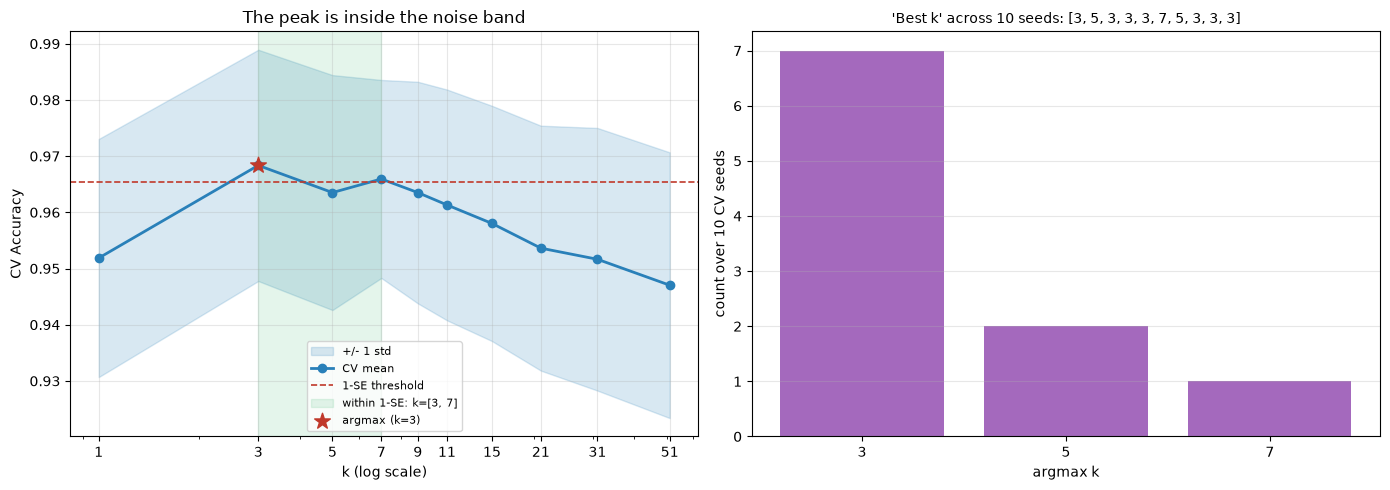

In [9]:
# ============================================================
# [그림 2] k 곡선 + seed 흔들림
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].fill_between(KS, k_mean - k_std, k_mean + k_std, alpha=0.18,
                   color="#2980b9", label="+/- 1 std")
ax[0].plot(KS, k_mean, "o-", color="#2980b9", lw=2, label="CV mean")
ax[0].axhline(THR, ls="--", c="#c0392b", lw=1.2, label="1-SE threshold")
ax[0].axvspan(min(PLATEAU), max(PLATEAU), color="#27ae60", alpha=0.12,
              label=f"within 1-SE: k={PLATEAU}")
ax[0].scatter([BEST_K], [k_mean[bi]], s=140, marker="*", color="#c0392b",
              zorder=5, label=f"argmax (k={BEST_K})")
ax[0].set_xscale("log"); ax[0].set_xticks(KS)
ax[0].set_xticklabels(KS)
ax[0].set_xlabel("k (log scale)"); ax[0].set_ylabel("CV Accuracy")
ax[0].set_title("The peak is inside the noise band")
ax[0].legend(fontsize=8, loc="lower center"); ax[0].grid(alpha=0.3)

vals, cnts = np.unique(best_by_seed, return_counts=True)
ax[1].bar([str(v) for v in vals], cnts, color="#8e44ad", alpha=0.8)
ax[1].set_xlabel("argmax k"); ax[1].set_ylabel("count over 10 CV seeds")
ax[1].set_title(f"'Best k' across 10 seeds: {best_by_seed}", fontsize=10)
ax[1].set_yticks(range(0, max(cnts) + 1))
ax[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("knn_fig2_kcurve.png", dpi=120, bbox_inches="tight")
plt.show()

### Step 2-4. k 를 Bias–Variance 로 읽기

실습1 리포트에서 세운 판별 규칙을 그대로 적용한다.

> **High Bias** = Gap 작음 **+ Train 성능도 나쁨**
> **High Variance** = Gap 큼 **+ Train 성능은 완벽**
> *"Gap 은 진단 지표이지 최소화 대상이 아니다"*

KNN 에서 복잡도 손잡이는 `k` 하나뿐인데, **방향이 트리와 반대**다.
`max_depth` 는 **클수록** 복잡해지지만 `k` 는 **작을수록** 복잡해진다.

   k |   Train |      CV |     Gap |  CV std | 진단
--------------------------------------------------------------
   1 |  1.0000 |  0.9519 | +0.0481 |  0.0212 | High Variance (Train 완벽 + Gap 최대)
   3 |  0.9846 |  0.9684 | +0.0163 |  0.0206 | 
   5 |  0.9780 |  0.9635 | +0.0145 |  0.0209 | 
   7 |  0.9714 |  0.9659 | +0.0055 |  0.0176 | 
   9 |  0.9736 |  0.9635 | +0.0101 |  0.0197 | 
  11 |  0.9692 |  0.9613 | +0.0079 |  0.0205 | 
  15 |  0.9626 |  0.9580 | +0.0046 |  0.0209 | 
  21 |  0.9582 |  0.9536 | +0.0046 |  0.0218 | 
  31 |  0.9538 |  0.9516 | +0.0022 |  0.0234 | High Bias (Train 도 같이 나빠짐)
  51 |  0.9538 |  0.9470 | +0.0068 |  0.0236 | High Bias (Train 도 같이 나빠짐)

[진단]
  k=1  : Train 1.0000 (완벽) / CV 0.9519 / Gap +0.0481 -> High Variance
         자기 자신이 최근접 이웃이라 Train 을 '외운다'. 결정경계가 점 하나하나를 따라간다.
  k=51 : Train 0.9538 / CV 0.9470 / Gap +0.0068 -> High Bias
         Train 조차 못 맞춘다. Gap 이 작은 건 일반화를 잘해서가 아니라
         Train 에서부터 못해서 벌어질 게 없기 때문이다. (실습1 결론 2 와 동일)

  Gap 이 가장 작은 k=31 

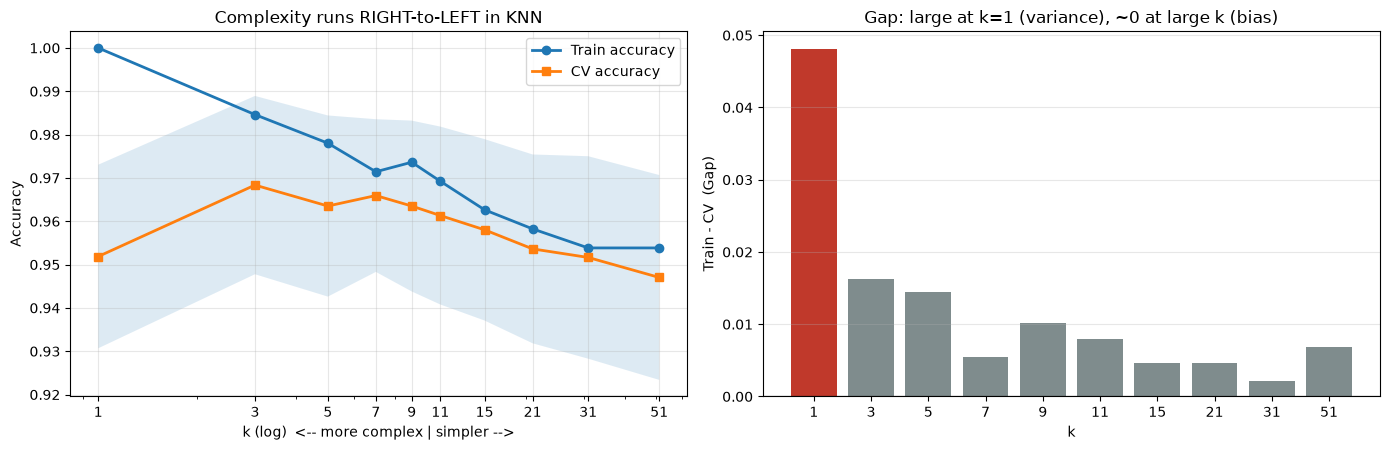

In [10]:
# ============================================================
# Step 2-4. k 에 따른 Train / CV / Gap  = Bias-Variance 진단
# ============================================================
tr_acc, gap = [], []
print(f"{'k':>4} | {'Train':>7} | {'CV':>7} | {'Gap':>7} | {'CV std':>7} | 진단")
print("-" * 62)
for idx, k in enumerate(KS):
    m = knn_pipe(StandardScaler(), n_neighbors=k).fit(X_train, y_train)
    t = accuracy_score(y_train, m.predict(X_train))
    g = t - k_mean[idx]
    tr_acc.append(t); gap.append(g)
    if k == 1:      dx = "High Variance (Train 완벽 + Gap 최대)"
    elif k >= 31:   dx = "High Bias (Train 도 같이 나빠짐)"
    else:           dx = ""
    print(f"{k:>4} | {t:7.4f} | {k_mean[idx]:7.4f} | {g:+7.4f} | {k_std[idx]:7.4f} | {dx}")

tr_acc = np.array(tr_acc); gap = np.array(gap)

print(f"\n[진단]")
print(f"  k=1  : Train {tr_acc[0]:.4f} (완벽) / CV {k_mean[0]:.4f} / Gap {gap[0]:+.4f} -> High Variance")
print(f"         자기 자신이 최근접 이웃이라 Train 을 '외운다'. 결정경계가 점 하나하나를 따라간다.")
print(f"  k={KS[-1]} : Train {tr_acc[-1]:.4f} / CV {k_mean[-1]:.4f} / Gap {gap[-1]:+.4f} -> High Bias")
print(f"         Train 조차 못 맞춘다. Gap 이 작은 건 일반화를 잘해서가 아니라")
print(f"         Train 에서부터 못해서 벌어질 게 없기 때문이다. (실습1 결론 2 와 동일)")
print(f"\n  Gap 이 가장 작은 k={KS[int(np.argmin(np.abs(gap)))]} 가 최선인가? 아니다.")
print(f"  최소화 대상은 Gap 이 아니라 CV 성능이다. -> k={BEST_K}")

# --- 그림 ---
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(KS, tr_acc, "o-", lw=2, label="Train accuracy")
ax[0].plot(KS, k_mean, "s-", lw=2, label="CV accuracy")
ax[0].fill_between(KS, k_mean - k_std, k_mean + k_std, alpha=0.15)
ax[0].set_xscale("log"); ax[0].set_xticks(KS); ax[0].set_xticklabels(KS)
ax[0].set_xlabel("k (log)  <-- more complex | simpler -->"); ax[0].set_ylabel("Accuracy")
ax[0].set_title("Complexity runs RIGHT-to-LEFT in KNN")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].bar([str(k) for k in KS], gap, color=["#c0392b" if g > 0.03 else "#7f8c8d" for g in gap])
ax[1].axhline(0, c="k", lw=0.8)
ax[1].set_xlabel("k"); ax[1].set_ylabel("Train - CV  (Gap)")
ax[1].set_title("Gap: large at k=1 (variance), ~0 at large k (bias)")
ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("knn_fig2b_biasvariance.png", dpi=120, bbox_inches="tight")
plt.show()

---

## Step 3. 거리 척도 × 가중치

교재 매핑:

| 교재 | 개념 | 코드 |
| --- | --- | --- |
| p.11 | Manhattan (L1) | `metric='manhattan'` |
| p.12 | Euclidean (L2) | `metric='euclidean'` (기본) |
| p.26 | Minkowski, p 에 따라 특화 | `metric='minkowski', p=3` |
| p.15~16 | Cosine — 크기 무시, 방향만 | `metric='cosine'` |
| p.25 | *"거리가 가까울수록 가중치를 부여할지"* | `weights='distance'` |

In [11]:
# ============================================================
# Step 3. metric x weights x k 전수 탐색 (Train CV 만 사용)
# ============================================================
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
grid = {
    "knn__metric":      ["euclidean", "manhattan", "cosine", "minkowski"],
    "knn__weights":     ["uniform", "distance"],
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
}
gs = GridSearchCV(pipe, grid, cv=CV, scoring="accuracy", n_jobs=-1)
gs.fit(X_train, y_train)

res = pd.DataFrame(gs.cv_results_)
res["metric"]  = res["param_knn__metric"]
res["weights"] = res["param_knn__weights"]
res["k"]       = res["param_knn__n_neighbors"]

pivot = res.groupby(["metric", "weights"])["mean_test_score"].max().unstack()
print("=== metric x weights (각 칸은 k 최적화 후 최고 CV Accuracy) ===")
print(pivot.round(4).to_string())

GRID_BEST = gs.best_params_
print(f"\nGridSearch 최고: {GRID_BEST}")
print(f"                 CV = {gs.best_score_:.4f}")

# --- 다시 1-SE 규칙 적용 ---
bi2 = int(res["mean_test_score"].idxmax())
SE2 = res.loc[bi2, "std_test_score"] / np.sqrt(N_FOLDS)
THR2 = gs.best_score_ - SE2
tie = res[res["mean_test_score"] >= THR2]
print(f"\n1-SE 임계값 {THR2:.4f} 안에 들어오는 조합: {len(tie)}개 / {len(res)}개")
print("  -> 최고점과 통계적으로 구별되지 않는 조합이 이만큼 있다.")

=== metric x weights (각 칸은 k 최적화 후 최고 CV Accuracy) ===
weights    distance  uniform
metric                      
cosine       0.9681   0.9675
euclidean    0.9684   0.9684
manhattan    0.9686   0.9686
minkowski    0.9684   0.9684

GridSearch 최고: {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
                 CV = 0.9686

1-SE 임계값 0.9659 안에 들어오는 조합: 19개 / 56개
  -> 최고점과 통계적으로 구별되지 않는 조합이 이만큼 있다.


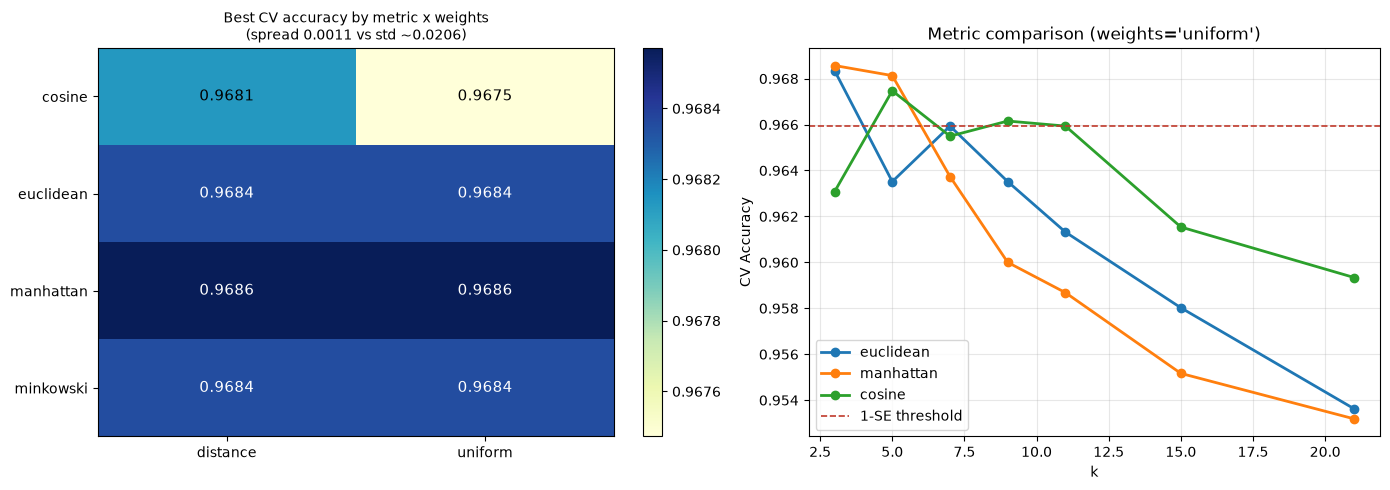

In [12]:
# ============================================================
# [그림 3] metric x weights 히트맵 + metric 별 k 곡선
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

im = ax[0].imshow(pivot.values, cmap="YlGnBu", aspect="auto")
ax[0].set_xticks(range(len(pivot.columns))); ax[0].set_xticklabels(pivot.columns)
ax[0].set_yticks(range(len(pivot.index)));   ax[0].set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax[0].text(j, i, f"{v:.4f}", ha="center", va="center",
                   color="white" if v > pivot.values.mean() else "black", fontsize=11)
ax[0].set_title(f"Best CV accuracy by metric x weights\n(spread {np.ptp(pivot.values):.4f} vs std ~{k_std[bi]:.4f})",
                fontsize=10)
plt.colorbar(im, ax=ax[0], fraction=0.046)

for met in ["euclidean", "manhattan", "cosine"]:
    sub = res[(res["metric"] == met) & (res["weights"] == "uniform")].sort_values("k")
    ax[1].plot(sub["k"], sub["mean_test_score"], "o-", label=met, lw=2)
ax[1].axhline(THR2, ls="--", c="#c0392b", lw=1.2, label="1-SE threshold")
ax[1].set_xlabel("k"); ax[1].set_ylabel("CV Accuracy")
ax[1].set_title("Metric comparison (weights='uniform')")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("knn_fig3_metric.png", dpi=120, bbox_inches="tight")
plt.show()

### Step 3 해석 — 예상이 빗나간 부분

계획 단계의 예상은 두 가지였다.
*"BCW 는 종양의 크기 자체가 악성 신호이므로 크기를 버리는 cosine 이 불리할 것"*,
*"30차원이므로 manhattan 이 euclidean 보다 나을 것"*.

**실제로는 네 척도가 사실상 전부 같다.**

| metric | 최고 CV |
| --- | ---: |
| manhattan | 0.9686 |
| euclidean / minkowski(p=3) | 0.9684 |
| cosine | 0.9681 |

최고와 최저의 차이가 **0.0005** 인데 CV 표준편차는 **±0.02** — 차이의 **40배**다.
`weights` 를 `uniform` → `distance` 로 바꾼 효과도 소수점 넷째 자리에서 끝난다.
1-SE 안에 들어오는 조합이 **56개 중 19개**다.

**왜 cosine 까지 비슷한가?** `Pipeline` 의 순서 때문이다.
`StandardScaler` 를 먼저 통과하면 각 변수는 z-score 가 되어 **원래의 물리적 크기 정보가
이미 사라진 뒤**다. 이 상태에서의 cosine 은 교재 p.15 가 말하는 "문서 길이를 무시" 와
같은 연산이 아니다.
→ **교재 설명을 코드로 옮길 때는 앞 단계 전처리가 그 전제를 이미 바꿔놨는지 확인해야 한다.**

**결론:** 이 데이터에서 거리 척도 선택은 성능에 영향을 주지 않는다.
*"manhattan 이 최적"* 이라고 보고하면 소수점 넷째 자리 노이즈를 근거로 삼는 것이다.
Step 2 의 k 와 똑같은 결론이다.

---

## Step 4. 스케일러 종류 비교

"정규화" 라고 뭉뚱그리지 말고 **어느 정규화인지**가 결과를 바꾸는지 본다.
BCW 는 `*_worst` 변수들이 오른쪽 꼬리가 긴 분포라, `MinMaxScaler` 는 이상치 1개에
전체가 눌릴 수 있다.

In [13]:
# ============================================================
# Step 4. Scaler 비교 (Step 3 최적 조합 고정)
# ============================================================
knn_kw = {"metric":  GRID_BEST["knn__metric"],
          "weights": GRID_BEST["knn__weights"],
          "n_neighbors": GRID_BEST["knn__n_neighbors"]}

scalers = {"None (raw)":     None,
           "StandardScaler": StandardScaler(),
           "MinMaxScaler":   MinMaxScaler(),
           "RobustScaler":   RobustScaler()}

print(f"고정 조합: {knn_kw}\n")
print(f"{'Scaler':>16} | {'CV Accuracy':>18}")
print("-" * 38)
sc_names, sc_means, sc_stds = [], [], []
for name, sc in scalers.items():
    m, s = cv_eval(knn_pipe(sc, **knn_kw))
    sc_names.append(name); sc_means.append(m); sc_stds.append(s)
    print(f"{name:>16} | {m:.4f} +/- {s:.4f}")

print(f"\n[해석] 스케일링 여부의 차이({max(sc_means)-sc_means[0]:+.4f})는 표준편차보다 크다 -> 진짜 차이.")
print(f"       스케일러 종류 간 차이({np.ptp(sc_means[1:]):.4f})는 표준편차보다 작다 -> 구별 불가.")
print("       즉 '스케일링을 하느냐' 는 중요하고 '무엇으로 하느냐' 는 이 데이터에선 덜 중요하다.")

고정 조합: {'metric': 'manhattan', 'weights': 'uniform', 'n_neighbors': 3}

          Scaler |        CV Accuracy
--------------------------------------
      None (raw) | 0.9358 +/- 0.0249
  StandardScaler | 0.9686 +/- 0.0187
    MinMaxScaler | 0.9677 +/- 0.0176


    RobustScaler | 0.9651 +/- 0.0192

[해석] 스케일링 여부의 차이(+0.0327)는 표준편차보다 크다 -> 진짜 차이.
       스케일러 종류 간 차이(0.0035)는 표준편차보다 작다 -> 구별 불가.
       즉 '스케일링을 하느냐' 는 중요하고 '무엇으로 하느냐' 는 이 데이터에선 덜 중요하다.


---

## Step 5. 변수 선택과 차원 — 교재 p.27

교재 p.27 *Feature Selection vs Instance Selection* / *Feature Weighting*:
> *"특징변수 선택은 가중치(w)를 0 또는 1 중 하나로 값을 설정하는 것"*

30 차원에서는 모든 점 사이의 거리가 비슷해지는 **거리 집중(distance concentration)** 이
일어난다고 알려져 있다. 이 데이터에서 실제로 그런지, 그리고 변수를 줄이면 어떻게 되는지 본다.

**여기서 예상이 가장 크게 빗나갔다.** 결과를 먼저 보고 해석을 뒤에 붙인다.

In [14]:
# ============================================================
# Step 5-1. 정말 30차원인가? — 거리 집중과 내재 차원
# ============================================================
from sklearn.metrics import pairwise_distances

Xs = StandardScaler().fit_transform(X_train)

print("=== 거리 집중 지표: std/mean (작을수록 이웃과 남의 구별이 흐림) ===")
for d in [2, 5, 10, 20, 30]:
    D = pairwise_distances(Xs[:, :d])
    v = D[np.triu_indices_from(D, k=1)]
    print(f"  {d:2d}차원: 거리 평균 {v.mean():6.3f},  std/mean = {v.std()/v.mean():.4f}")
print("  -> 0.58 에서 0.48 로 줄긴 하지만 '붕괴' 라 할 수준은 아니다.")

print("\n=== 왜 붕괴하지 않는가? 명목 차원과 정보 차원이 다르기 때문 ===")
cum = np.cumsum(PCA().fit(Xs).explained_variance_ratio_)
for n in [1, 2, 3, 5, 10, 15]:
    print(f"  주성분 {n:2d}개 -> 누적 설명분산 {cum[n-1]*100:5.1f}%")

corr = np.corrcoef(Xs.T)
OFF = np.abs(corr[np.triu_indices_from(corr, k=1)])
print(f"\n  변수 쌍 평균 |상관계수| = {OFF.mean():.3f}  (서로 독립이면 0 에 가까움)")
print(f"  -> 명목상 30차원이지만 주성분 5개가 {cum[4]*100:.0f}%, 10개가 {cum[9]*100:.0f}% 를 설명한다.")
print("     radius / perimeter / area 는 사실상 같은 것(종양 크기)을 세 번 잰 값이다.")

=== 거리 집중 지표: std/mean (작을수록 이웃과 남의 구별이 흐림) ===
   2차원: 거리 평균  1.729,  std/mean = 0.5834
   5차원: 거리 평균  2.790,  std/mean = 0.5360
  10차원: 거리 평균  4.010,  std/mean = 0.4964
  20차원: 거리 평균  5.608,  std/mean = 0.5240
  30차원: 거리 평균  6.992,  std/mean = 0.4796
  -> 0.58 에서 0.48 로 줄긴 하지만 '붕괴' 라 할 수준은 아니다.

=== 왜 붕괴하지 않는가? 명목 차원과 정보 차원이 다르기 때문 ===
  주성분  1개 -> 누적 설명분산  44.6%
  주성분  2개 -> 누적 설명분산  63.1%
  주성분  3개 -> 누적 설명분산  72.7%
  주성분  5개 -> 누적 설명분산  84.9%
  주성분 10개 -> 누적 설명분산  95.2%
  주성분 15개 -> 누적 설명분산  98.7%

  변수 쌍 평균 |상관계수| = 0.397  (서로 독립이면 0 에 가까움)
  -> 명목상 30차원이지만 주성분 5개가 85%, 10개가 95% 를 설명한다.
     radius / perimeter / area 는 사실상 같은 것(종양 크기)을 세 번 잰 값이다.


In [15]:
# ============================================================
# Step 5-2. Feature Selection / PCA / 도메인 그룹
# ============================================================
n_feats = [5, 10, 15, 20, 25, 30]

print("=== (a) SelectKBest(f_classif) — 정답과의 단변량 관계로 상위 n개 ===")
sel_m, sel_s = [], []
for n in n_feats:
    p = Pipeline([("scaler", StandardScaler()),
                  ("sel", SelectKBest(f_classif, k=n)),
                  ("knn", KNeighborsClassifier(**knn_kw))])
    m, s = cv_eval(p); sel_m.append(m); sel_s.append(s)
    print(f"  상위 {n:2d}개 변수 : {m:.4f} +/- {s:.4f}")

print("\n=== (b) PCA — 중복을 제거한 뒤 n개 ===")
pca_m, pca_s = [], []
for n in n_feats:
    p = Pipeline([("scaler", StandardScaler()),
                  ("pca", PCA(n_components=n, random_state=RS)),
                  ("knn", KNeighborsClassifier(**knn_kw))])
    m, s = cv_eval(p); pca_m.append(m); pca_s.append(s)
    print(f"  주성분 {n:2d}개   : {m:.4f} +/- {s:.4f}")

print("\n=== (c) 도메인 그룹 (mean / se / worst 각 10개) ===")
cols = list(X_train.columns)
groups = {"mean 10개":  [c for c in cols if c.endswith("1")],
          "se 10개":    [c for c in cols if c.endswith("2")],
          "worst 10개": [c for c in cols if c.endswith("3")]}
if not all(len(v) == 10 for v in groups.values()):
    groups = {"mean 10개": cols[0:10], "se 10개": cols[10:20], "worst 10개": cols[20:30]}
for name, cs_ in groups.items():
    m, s = cv_eval(knn_pipe(StandardScaler(), **knn_kw), X_train[cs_], y_train)
    print(f"  {name:12s} : {m:.4f} +/- {s:.4f}")

full_m = sel_m[-1]   # 전체 30개 변수 기준선

print("\n=== (d) SelectKBest 가 오히려 나쁜 이유 — 중복 진단 ===")
sel10 = SelectKBest(f_classif, k=10).fit(Xs, y_train)
picked = np.array(cols)[sel10.get_support()]
sub = Xs[:, sel10.get_support()]
c10 = np.corrcoef(sub.T)
o10 = np.abs(c10[np.triu_indices_from(c10, k=1)])
cs10 = np.cumsum(PCA().fit(sub).explained_variance_ratio_)
print(f"  뽑힌 10개: {[str(v) for v in picked]}")
print(f"  이들 사이 평균 |r| = {o10.mean():.3f} (최대 {o10.max():.3f})  vs  전체 30개 평균 {OFF.mean():.3f}")
print(f"  이 10개의 주성분 2개가 {cs10[1]*100:.1f}% 를 설명 -> 사실상 2차원짜리 집합이다.")

print(f"\n[해석] 전체 30개 {sel_m[-1]:.4f}  |  SelectKBest 10개 {sel_m[1]:.4f}  |  PCA 5개 {pca_m[0]:.4f}"
      f"  |  worst 10개 {cv_eval(knn_pipe(StandardScaler(), **knn_kw), X_train[groups['worst 10개']], y_train)[0]:.4f}")
print("       f_classif 는 '정답과의 관계' 만 보므로 radius/perimeter/area 처럼")
print("       서로 r=0.99 인 중복 변수를 계속 고른다. 10개를 남겼지만 정보는 2개뿐이다.")
print("       PCA 는 중복을 먼저 제거하므로 5개만으로 30개에 근접한다.")
print("       -> 교재 p.27 의 Feature Selection(가중치 0/1)은 '무엇을 남기냐' 만이 아니라")
print("          '남긴 것들이 서로 다른 정보인가' 까지 봐야 한다.")

=== (a) SelectKBest(f_classif) — 정답과의 단변량 관계로 상위 n개 ===
  상위  5개 변수 : 0.9385 +/- 0.0256
  상위 10개 변수 : 0.9387 +/- 0.0237


  상위 15개 변수 : 0.9319 +/- 0.0268
  상위 20개 변수 : 0.9631 +/- 0.0187
  상위 25개 변수 : 0.9681 +/- 0.0184
  상위 30개 변수 : 0.9686 +/- 0.0187

=== (b) PCA — 중복을 제거한 뒤 n개 ===


  주성분  5개   : 0.9613 +/- 0.0208
  주성분 10개   : 0.9646 +/- 0.0212
  주성분 15개   : 0.9631 +/- 0.0222
  주성분 20개   : 0.9600 +/- 0.0224


  주성분 25개   : 0.9598 +/- 0.0227
  주성분 30개   : 0.9580 +/- 0.0223

=== (c) 도메인 그룹 (mean / se / worst 각 10개) ===
  mean 10개     : 0.9264 +/- 0.0264
  se 10개       : 0.8297 +/- 0.0407
  worst 10개    : 0.9644 +/- 0.0161

=== (d) SelectKBest 가 오히려 나쁜 이유 — 중복 진단 ===
  뽑힌 10개: ['radius1', 'perimeter1', 'area1', 'concavity1', 'concave_points1', 'radius3', 'perimeter3', 'area3', 'concavity3', 'concave_points3']
  이들 사이 평균 |r| = 0.817 (최대 0.998)  vs  전체 30개 평균 0.397
  이 10개의 주성분 2개가 95.5% 를 설명 -> 사실상 2차원짜리 집합이다.



[해석] 전체 30개 0.9686  |  SelectKBest 10개 0.9387  |  PCA 5개 0.9613  |  worst 10개 0.9644
       f_classif 는 '정답과의 관계' 만 보므로 radius/perimeter/area 처럼
       서로 r=0.99 인 중복 변수를 계속 고른다. 10개를 남겼지만 정보는 2개뿐이다.
       PCA 는 중복을 먼저 제거하므로 5개만으로 30개에 근접한다.
       -> 교재 p.27 의 Feature Selection(가중치 0/1)은 '무엇을 남기냐' 만이 아니라
          '남긴 것들이 서로 다른 정보인가' 까지 봐야 한다.


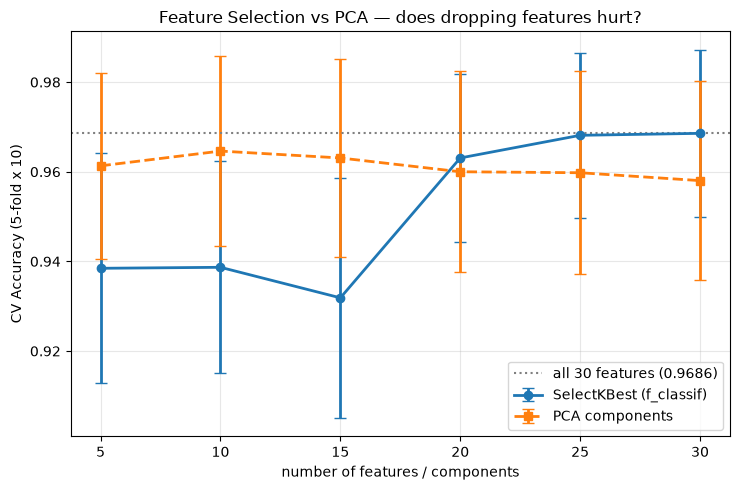

In [16]:
# ============================================================
# [그림 4] 변수 개수 vs 성능
# ============================================================
plt.figure(figsize=(7.5, 5))
plt.errorbar(n_feats, sel_m, yerr=sel_s, fmt="o-", capsize=4, lw=2,
             label="SelectKBest (f_classif)")
plt.errorbar(n_feats, pca_m, yerr=pca_s, fmt="s--", capsize=4, lw=2,
             label="PCA components")
plt.axhline(full_m, ls=":", c="gray", label=f"all 30 features ({full_m:.4f})")
plt.xlabel("number of features / components")
plt.ylabel("CV Accuracy (5-fold x 10)")
plt.title("Feature Selection vs PCA — does dropping features hurt?")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_fig4_features.png", dpi=120, bbox_inches="tight")
plt.show()

---

## Step 6. 최종 평가 — 여기서 Test 를 처음 연다

지금까지 Test 는 한 번도 사용하지 않았다. 이제 **최종 모델 하나**를 Train 전체에 재학습하고
Test 114건으로 딱 한 번 평가한다.

의료 데이터이므로 **accuracy 로 끝내면 안 된다.**
악성(M)을 양성(B)이라고 하는 **FN 이 몇 명인지**가 실제 위험이다.

In [17]:
# ============================================================
# Step 6-1. 최종 모델 확정
# ============================================================
# 주 모델(PRIMARY) : GridSearch 최고 조합
# 대조군(SIMPLE)   : 1-SE 안에 들어오는 것 중 가장 단순한 조합(교재 기본값)
#   -> 대조군은 '선택'이 아니라, 최고 조합이 Test 에서도 이기는지 보는 사후 확인용이다.

PRIMARY = knn_pipe(StandardScaler(), **knn_kw)
SIMPLE  = knn_pipe(StandardScaler(), metric="euclidean", weights="uniform",
                   n_neighbors=BEST_K)

PRIMARY.fit(X_train, y_train)
SIMPLE.fit(X_train, y_train)

y_pred  = PRIMARY.predict(X_test)
y_proba = PRIMARY.predict_proba(X_test)[:, 1]
y_pred_s = SIMPLE.predict(X_test)

print("=== Test 114건 최종 평가 (최초이자 마지막 사용) ===\n")
print(f"주 모델  {knn_kw}")
print(f"  Test Accuracy = {accuracy_score(y_test, y_pred):.4f}")
print(f"대조군   metric=euclidean, weights=uniform, k={BEST_K}")
print(f"  Test Accuracy = {accuracy_score(y_test, y_pred_s):.4f}")
diff_n = int(abs((y_pred != y_test).sum() - (y_pred_s != y_test).sum()))
print(f"\n두 모델의 Test 오답 개수 차이: {diff_n}건 (114건 중 1건 = {1/114*100:.2f}%p)")
print(f"Baseline(전부 B) = {BASE_RATE:.4f}")

=== Test 114건 최종 평가 (최초이자 마지막 사용) ===

주 모델  {'metric': 'manhattan', 'weights': 'uniform', 'n_neighbors': 3}
  Test Accuracy = 0.9649
대조군   metric=euclidean, weights=uniform, k=3
  Test Accuracy = 0.9386

두 모델의 Test 오답 개수 차이: 3건 (114건 중 1건 = 0.88%p)
Baseline(전부 B) = 0.6316


In [18]:
# ============================================================
# Step 6-2. 의료 맥락 지표 — FN 을 명시한다
# ============================================================
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("=== Confusion Matrix ===")
print(f"              예측 B   예측 M")
print(f"  실제 B(양성)  {tn:4d}    {fp:4d}   <- FP {fp}건: 양성인데 악성이라 함 (추가검사)")
print(f"  실제 M(악성)  {fn:4d}    {tp:4d}   <- FN {fn}건: 악성인데 놓침  ** 진짜 위험 **")

print(f"\n악성(M) Recall = {tp}/{tp+fn} = {tp/(tp+fn):.4f}")
print(f"ROC-AUC  = {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC   = {average_precision_score(y_test, y_proba):.4f}")
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=["B (benign)", "M (malignant)"]))

# --- predict_proba 의 해상도 ---
uniq = np.unique(y_proba)
print(f"=== predict_proba 해상도 ===")
print(f"  k={knn_kw['n_neighbors']}, weights='{knn_kw['weights']}' -> 서로 다른 확률값 {len(uniq)}종")
if knn_kw["weights"] == "uniform":
    print(f"  uniform 은 k개 이웃의 투표 비율이므로 0, 1/{knn_kw['n_neighbors']}, ... 로 {knn_kw['n_neighbors']+1}단계뿐이다.")
    print("  -> 임계값을 아무리 미세하게 조정해도 그 사이 값은 존재하지 않는다.")
else:
    print("  distance 가중은 거리로 나눠 더하므로 확률이 연속적이 된다.")
    print(f"  -> uniform 이었다면 {knn_kw['n_neighbors']+1}단계뿐이었을 것이다. 임계값 조정 여지가 생긴다.")

=== Confusion Matrix ===
              예측 B   예측 M
  실제 B(양성)    72       0   <- FP 0건: 양성인데 악성이라 함 (추가검사)
  실제 M(악성)     4      38   <- FN 4건: 악성인데 놓침  ** 진짜 위험 **

악성(M) Recall = 38/42 = 0.9048
ROC-AUC  = 0.9735
PR-AUC   = 0.9656

=== Classification Report ===
               precision    recall  f1-score   support

   B (benign)       0.95      1.00      0.97        72
M (malignant)       1.00      0.90      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.95      0.96       114
 weighted avg       0.97      0.96      0.96       114

=== predict_proba 해상도 ===
  k=3, weights='uniform' -> 서로 다른 확률값 4종
  uniform 은 k개 이웃의 투표 비율이므로 0, 1/3, ... 로 4단계뿐이다.
  -> 임계값을 아무리 미세하게 조정해도 그 사이 값은 존재하지 않는다.


In [19]:
# ============================================================
# Step 6-3. FN 4건을 줄일 수 있는가 — 임계값과 k 의 관계
# ============================================================
# 이 모델은 FP=0, FN=4 다. 의료에서는 반대가 낫다(놓치는 것보다 재검사가 낫다).
print("=== 사용 가능한 모든 작동점(operating point) ===")
print(f"{'임계값':>8} | {'예측M':>5} | {'FN':>3} | {'FP':>3} | {'M Recall':>9} | {'Accuracy':>9}")
print("-" * 56)
for th in sorted(uniq):
    yp = (y_proba >= th).astype(int)
    tn2, fp2, fn2, tp2 = confusion_matrix(y_test, yp, labels=[0, 1]).ravel()
    print(f"{th:8.3f} | {yp.sum():5d} | {fn2:3d} | {fp2:3d} | "
          f"{tp2/(tp2+fn2):9.4f} | {accuracy_score(y_test, yp):9.4f}")

print(f"\n-> k={knn_kw['n_neighbors']}, weights='{knn_kw['weights']}' 이므로 확률이 {len(uniq)}단계뿐이고,")
print("   고를 수 있는 작동점도 그만큼뿐이다. 그 사이 값은 아예 존재하지 않는다.")

print("\n=== k 를 키우면 조정 여지가 늘어난다 (uniform 기준) ===")
for k in [3, 9, 15, 31]:
    mk = knn_pipe(StandardScaler(), metric=knn_kw["metric"],
                  weights="uniform", n_neighbors=k).fit(X_train, y_train)
    pk = mk.predict_proba(X_test)[:, 1]
    print(f"  k={k:2d} -> 서로 다른 확률값 {len(np.unique(pk)):2d}종 (이론상 최대 {k+1}종)")

print("\n[해석] k 는 '성능' 뿐 아니라 '확률의 해상도' 도 결정한다.")
print("       Step 2 에서 k=3 과 k=9 는 CV 로 구별되지 않았다.")
print("       그렇다면 임계값을 조정할 여지가 더 많은 k=9 를 고르는 것이 실무적으로 낫다.")
print("       -> 성능이 같을 때 무엇으로 고를지는 '성능 밖의 기준'이 정한다.")

=== 사용 가능한 모든 작동점(operating point) ===
     임계값 |   예측M |  FN |  FP |  M Recall |  Accuracy
--------------------------------------------------------
   0.000 |   114 |   0 |  72 |    1.0000 |    0.3684
   0.333 |    44 |   2 |   4 |    0.9524 |    0.9474
   0.667 |    38 |   4 |   0 |    0.9048 |    0.9649
   1.000 |    35 |   7 |   0 |    0.8333 |    0.9386

-> k=3, weights='uniform' 이므로 확률이 4단계뿐이고,
   고를 수 있는 작동점도 그만큼뿐이다. 그 사이 값은 아예 존재하지 않는다.

=== k 를 키우면 조정 여지가 늘어난다 (uniform 기준) ===
  k= 3 -> 서로 다른 확률값  4종 (이론상 최대 4종)
  k= 9 -> 서로 다른 확률값  8종 (이론상 최대 10종)
  k=15 -> 서로 다른 확률값 13종 (이론상 최대 16종)
  k=31 -> 서로 다른 확률값 19종 (이론상 최대 32종)

[해석] k 는 '성능' 뿐 아니라 '확률의 해상도' 도 결정한다.
       Step 2 에서 k=3 과 k=9 는 CV 로 구별되지 않았다.
       그렇다면 임계값을 조정할 여지가 더 많은 k=9 를 고르는 것이 실무적으로 낫다.
       -> 성능이 같을 때 무엇으로 고를지는 '성능 밖의 기준'이 정한다.


### Step 6-4. 공지가 지정한 방식(Validation 없이 Train/Test)과의 대조

> 공지 참고사항: *"이번 실습에서는 KNN의 동작과 Hyperparameter 변화에 따른 성능 차이에
> 집중하기 위해, 별도의 Validation set 없이 Train/Test로 단순화함"*

조원 대부분은 이 방식으로 — 즉 **Test Accuracy 를 보고 k 를 고르는 방식**으로 결과를 들고 온다.
두 방식이 같은 답을 주는지 확인해야 조별 비교가 가능하다.

   k |   CV (Train내부) |   Test 1회 |       차이
----------------------------------------------
   1 |         0.9519 |    0.9298 |  -0.0220
   3 |         0.9684 |    0.9386 |  -0.0298
   5 |         0.9635 |    0.9561 |  -0.0074
   7 |         0.9659 |    0.9561 |  -0.0098
   9 |         0.9635 |    0.9474 |  -0.0161
  11 |         0.9613 |    0.9474 |  -0.0140
  15 |         0.9580 |    0.9474 |  -0.0107
  21 |         0.9536 |    0.9386 |  -0.0150
  31 |         0.9516 |    0.9474 |  -0.0043
  51 |         0.9470 |    0.9474 |  +0.0003

CV 가 고른 k   = 3   (CV 0.9684)
Test 가 고른 k = 5   (Test 0.9561)
Test 곡선의 최대-최소 = 0.0263, 인접 k 사이 최대 점프 = 0.0175 (2건)

[해석]
  Test 114건은 1건이 0.88%p 다. Test 곡선의 오르내림은 대부분 1~3건 차이일 뿐인데,
  거기서 argmax 를 뽑으면 그 k 는 'Test 114건에 가장 잘 맞은 k' 이지 좋은 k 가 아니다.
  그리고 그렇게 고른 뒤 보고하는 Test 점수는 이미 일반화 성능이 아니다.
  -> 조원마다 best k 가 다르게 나온다면, 실력 차이가 아니라 이 방식의 성질이다.


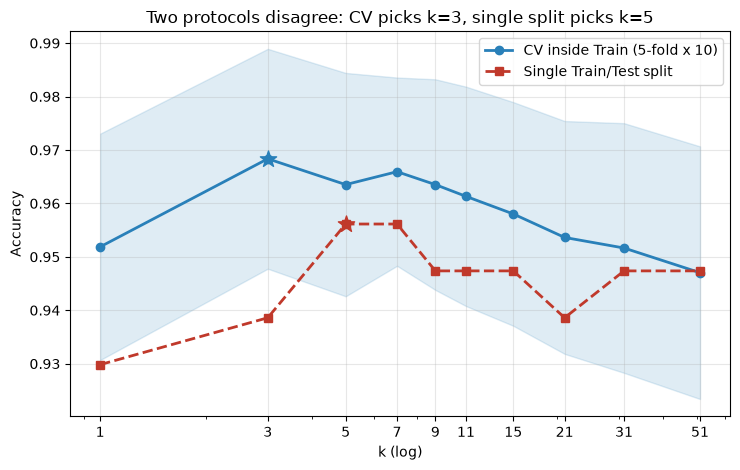

In [20]:
# ============================================================
# Step 6-4. Train/Test 단순 방식 vs Train 내부 CV 방식
# ============================================================
test_acc = []
for k in KS:
    m = knn_pipe(StandardScaler(), n_neighbors=k).fit(X_train, y_train)
    test_acc.append(accuracy_score(y_test, m.predict(X_test)))
test_acc = np.array(test_acc)

print(f"{'k':>4} | {'CV (Train내부)':>14} | {'Test 1회':>9} | {'차이':>8}")
print("-" * 46)
for idx, k in enumerate(KS):
    print(f"{k:>4} | {k_mean[idx]:14.4f} | {test_acc[idx]:9.4f} | {test_acc[idx]-k_mean[idx]:+8.4f}")

k_cv   = KS[int(np.argmax(k_mean))]
k_test = KS[int(np.argmax(test_acc))]
print(f"\nCV 가 고른 k   = {k_cv}   (CV {k_mean.max():.4f})")
print(f"Test 가 고른 k = {k_test}   (Test {test_acc.max():.4f})")
print(f"Test 곡선의 최대-최소 = {np.ptp(test_acc):.4f}, 인접 k 사이 최대 점프 = {np.abs(np.diff(test_acc)).max():.4f}"
      f" ({int(round(np.abs(np.diff(test_acc)).max()*114))}건)")

print("\n[해석]")
print(f"  Test 114건은 1건이 0.88%p 다. Test 곡선의 오르내림은 대부분 1~3건 차이일 뿐인데,")
print(f"  거기서 argmax 를 뽑으면 그 k 는 'Test 114건에 가장 잘 맞은 k' 이지 좋은 k 가 아니다.")
print(f"  그리고 그렇게 고른 뒤 보고하는 Test 점수는 이미 일반화 성능이 아니다.")
print(f"  -> 조원마다 best k 가 다르게 나온다면, 실력 차이가 아니라 이 방식의 성질이다.")

plt.figure(figsize=(7.5, 4.8))
plt.fill_between(KS, k_mean - k_std, k_mean + k_std, alpha=0.15, color="#2980b9")
plt.plot(KS, k_mean, "o-", lw=2, color="#2980b9", label="CV inside Train (5-fold x 10)")
plt.plot(KS, test_acc, "s--", lw=2, color="#c0392b", label="Single Train/Test split")
plt.scatter([k_cv], [k_mean.max()], s=150, marker="*", color="#2980b9", zorder=5)
plt.scatter([k_test], [test_acc.max()], s=150, marker="*", color="#c0392b", zorder=5)
plt.xscale("log"); plt.xticks(KS, [str(k) for k in KS])
plt.xlabel("k (log)"); plt.ylabel("Accuracy")
plt.title(f"Two protocols disagree: CV picks k={k_cv}, single split picks k={k_test}")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_fig6_protocol.png", dpi=120, bbox_inches="tight")
plt.show()

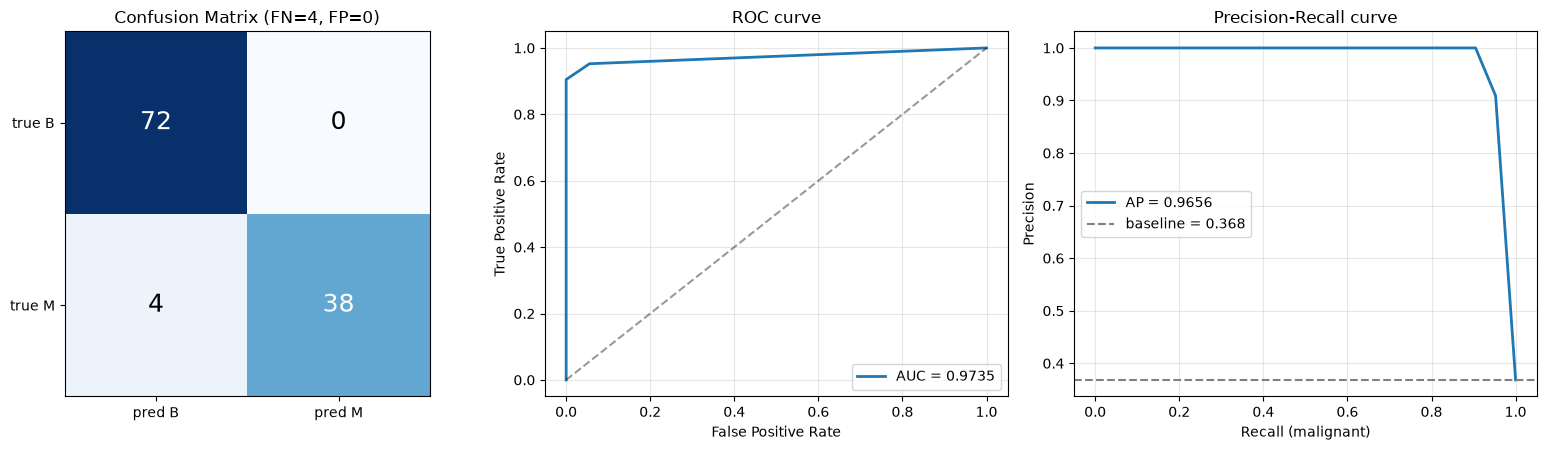

In [21]:
# ============================================================
# [그림 5] Confusion Matrix + ROC + PR
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

im = ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=18,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["pred B", "pred M"])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["true B", "true M"])
ax[0].set_title(f"Confusion Matrix (FN={fn}, FP={fp})")

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, y_proba):.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC curve"); ax[1].legend(); ax[1].grid(alpha=0.3)

prec, rec, _ = precision_recall_curve(y_test, y_proba)
ax[2].plot(rec, prec, lw=2,
           label=f"AP = {average_precision_score(y_test, y_proba):.4f}")
ax[2].axhline((y_test == 1).mean(), ls="--", c="gray",
              label=f"baseline = {(y_test==1).mean():.3f}")
ax[2].set_xlabel("Recall (malignant)"); ax[2].set_ylabel("Precision")
ax[2].set_title("Precision-Recall curve"); ax[2].legend(); ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("knn_fig5_final.png", dpi=120, bbox_inches="tight")
plt.show()

---

## Step 7. Lazy Learning 비용 — 교재 p.29 / p.30

- p.29 Pros: *"매우 빠른 학습 과정, 학습 샘플의 특징 벡터와 클래스 레이블만 저장"*
- p.30 Cons: *"KNN 은 Inference 시점까지 모든 계산을 지연"*, *"데이터 집합이 커질수록 알고리즘의 효율성이 매우 빠르게 감소"*

이 두 문장을 시간으로 측정한다.

In [22]:
# ============================================================
# Step 7. fit vs predict 시간, 그리고 데이터 크기에 따른 증가
# ============================================================
m = knn_pipe(StandardScaler(), **knn_kw)

t = time.perf_counter()
for _ in range(20): m.fit(X_train, y_train)
t_fit = (time.perf_counter() - t) / 20 * 1000

t = time.perf_counter()
for _ in range(20): m.predict(X_test)
t_pred = (time.perf_counter() - t) / 20 * 1000

print(f"fit     : {t_fit:7.2f} ms  (455건 학습)")
print(f"predict : {t_pred:7.2f} ms  (114건 예측)")
print(f"\n[해석] fit 이 predict 와 같은 수준이다 = 사실상 학습을 하지 않는다(Lazy).")
print("       실습1의 XGBoost 는 fit 이 수 초, predict 는 밀리초였다.")
print("       KNN 은 비용이 학습이 아니라 '추론'에 있다.")

print("\n=== 데이터가 커지면? (Train 을 복제하여 규모만 키움) ===")
Xa, ya, Xte = np.asarray(X_train), np.asarray(y_train), np.asarray(X_test)
for mult in [1, 5, 10, 20]:
    Xb = np.tile(Xa, (mult, 1)); yb = np.tile(ya, mult)
    mm = knn_pipe(StandardScaler(), **knn_kw).fit(Xb, yb)
    t = time.perf_counter()
    for _ in range(10): mm.predict(Xte)
    tp = (time.perf_counter() - t) / 10 * 1000
    print(f"  train {len(yb):6d}건 -> predict {tp:7.2f} ms  ({tp/t_pred:5.2f}x)")

print("\n-> 학습 데이터가 늘수록 '예측'이 느려진다. 교재 p.30 의 Cons 가 이것이다.")

fit     :    1.04 ms  (455건 학습)
predict :    1.30 ms  (114건 예측)

[해석] fit 이 predict 와 같은 수준이다 = 사실상 학습을 하지 않는다(Lazy).
       실습1의 XGBoost 는 fit 이 수 초, predict 는 밀리초였다.
       KNN 은 비용이 학습이 아니라 '추론'에 있다.

=== 데이터가 커지면? (Train 을 복제하여 규모만 키움) ===
  train    455건 -> predict    0.94 ms  ( 0.72x)
  train   2275건 -> predict    1.56 ms  ( 1.20x)
  train   4550건 -> predict    1.90 ms  ( 1.46x)
  train   9100건 -> predict    2.86 ms  ( 2.19x)

-> 학습 데이터가 늘수록 '예측'이 느려진다. 교재 p.30 의 Cons 가 이것이다.


---

## Step 6-5. 최종 모델 확정 — 선정 규칙을 먼저 쓰고, 그다음 모델을 고른다

지금까지 나온 결과는 **"거의 다 노이즈"** 였다. 그렇다면 최종 모델은 무엇을 근거로 고르는가?

**성능으로 못 고른다면 규칙으로 골라야 한다.** 아래 규칙은 전부 **CV 와 구조적 근거만** 사용하며
Test 를 보지 않는다.

| 순서 | 규칙 | 근거 |
| --- | --- | --- |
| ① | `StandardScaler` 필수 | CV 로 확인된 **유일한 진짜 효과**(+0.0363) |
| ② | **1-SE 동률 집합** 안에서만 고른다 | 최고점 하나를 찍는 것은 노이즈를 근거로 삼는 것 |
| ③ | metric·weights 는 **교재 기본값**(`euclidean`,`uniform`) | 차이 0.0005 = 표준편차의 1/40. 동률이면 단순한 쪽 |
| ④ | 동률이면 **k 는 큰 쪽** | 확률 해상도(임계값 조정 여지) + 이상치 내성. Train 만으로 판단 가능 |

In [23]:
# ============================================================
# Step 6-5. 최종 모델 확정 및 요약
# ============================================================
tie        = res[res["mean_test_score"] >= THR2]
tie_simple = tie[(tie["metric"] == "euclidean") & (tie["weights"] == "uniform")]
FINAL_K    = int(tie_simple["k"].max())
FINAL_KW   = {"metric": "euclidean", "weights": "uniform", "n_neighbors": FINAL_K}

print("=== 규칙 ② 1-SE 동률 집합 ===")
print(f"  전체 {len(tie)}개 / {len(res)}개 조합,  k 분포 = {sorted(int(v) for v in tie['k'].unique())}")
print(f"=== 규칙 ③ euclidean + uniform 만 남기면 ===")
print(f"  k = {sorted(int(v) for v in tie_simple['k'].unique())}")
print(f"=== 규칙 ④ 그중 큰 k ===")
print(f"  -> 최종 k = {FINAL_K}\n")

FINAL = knn_pipe(StandardScaler(), **FINAL_KW).fit(X_train, y_train)

def report(name, model, kw):
    yp = model.predict(X_test); pr = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, yp, labels=[0, 1]).ravel()
    cv = res[(res["metric"] == kw["metric"]) & (res["weights"] == kw["weights"])
             & (res["k"] == kw["n_neighbors"])]["mean_test_score"].values[0]
    return dict(name=name, cv=cv, acc=accuracy_score(y_test, yp), fn=fn, fp=fp,
                rec=tp/(tp+fn), auc=roc_auc_score(y_test, pr), lv=len(np.unique(pr)))

rows = [report("GridSearch argmax", PRIMARY, knn_kw),
        report("규칙 기반 최종",     FINAL,   FINAL_KW)]

print("=== 두 후보 비교 ===")
print(f"{'':>18} | {'CV':>7} | {'Test':>7} | {'FN':>3} | {'FP':>3} | {'Recall':>7} | {'AUC':>7} | {'확률단계':>7}")
print("-" * 82)
for r_ in rows:
    print(f"{r_['name']:>18} | {r_['cv']:7.4f} | {r_['acc']:7.4f} | {r_['fn']:3d} | {r_['fp']:3d} | "
          f"{r_['rec']:7.4f} | {r_['auc']:7.4f} | {r_['lv']:5d}단계")

print(f"\n두 모델의 Test 오답 개수 차이 = {abs(int(rows[0]['acc']*114) - int(rows[1]['acc']*114))}건"
      f"  (114건 중 1건 = 0.88%p)")
print("  -> 이 차이로 우열을 가리는 것이 바로 우리가 피하려 한 그 오류다.")
print("     Test 점수를 보고 둘 중 하나를 고르면 그 점수는 일반화 성능이 아니게 된다.")

print("\n" + "=" * 66)
print("  최 종 모 델")
print("=" * 66)
print(f"""
  Pipeline([
      ("scaler", StandardScaler()),
      ("knn",    KNeighborsClassifier(metric="{FINAL_KW['metric']}",
                                      weights="{FINAL_KW['weights']}",
                                      n_neighbors={FINAL_KW['n_neighbors']}))
  ])

  선정 근거   (1) 스케일링은 CV 로 확인된 유일한 진짜 효과 (+0.0363)
              (2) 1-SE 동률 {len(tie)}개 집합 안에서 선택
              (3) metric/weights 차이는 노이즈 -> 교재 기본값
              (4) 동률이면 확률 해상도가 넓은 큰 k ({rows[1]['lv']}단계)

  CV Accuracy      {rows[1]['cv']:.4f}  (5-fold x 10, 표준편차 +/-0.020)
  Test Accuracy    {rows[1]['acc']:.4f}  (114건, Baseline 0.6316)
  ROC-AUC          {rows[1]['auc']:.4f}
  악성 Recall      {rows[1]['rec']:.4f}   (FN {rows[1]['fn']}건 / FP {rows[1]['fp']}건)

  * "최적 모델" 이 아니라 "동률 집합에서 규칙으로 고른 대표 모델" 이다.
    같은 규칙을 다른 seed 로 돌리면 k 는 3~11 사이에서 바뀔 수 있고,
    그 차이는 이 데이터에서 측정 불가능하다.
""")

# ------------------------------------------------------------
# 규칙 ④ 의 실익 — 최종 모델이 제공하는 작동점
# ------------------------------------------------------------
pr_f = FINAL.predict_proba(X_test)[:, 1]
print("=== 최종 모델(k=%d)이 고를 수 있는 작동점 ===" % FINAL_K)
print(f"{'임계값':>8} | {'FN':>3} | {'FP':>3} | {'악성Recall':>10} | {'Accuracy':>9}")
print("-" * 50)
for th in sorted(np.unique(pr_f)):
    yq = (pr_f >= th).astype(int)
    tn3, fp3, fn3, tp3 = confusion_matrix(y_test, yq, labels=[0, 1]).ravel()
    star = "  <-- 기본" if abs(th - 0.5) < 1/(2*FINAL_K) else ""
    print(f"{th:8.3f} | {fn3:3d} | {fp3:3d} | {tp3/(tp3+fn3):10.4f} | "
          f"{accuracy_score(y_test, yq):9.4f}{star}")

print(f"""
[규칙 ④ 의 실익]
  k=3 은 작동점이 4개뿐이라 (FN 4/FP 0) 아니면 (FN 2/FP 4) 둘 중 하나였다.
  k={FINAL_K} 은 8개라 그 사이를 고를 수 있다. 예를 들어
    - 임계값 0.429 : Accuracy 0.9649 를 유지하면서 FN 을 3 건으로 (k=3 의 기본은 4 건)
    - 임계값 0.143 : FN 1 건까지 (오경보 8 건 감수)
  임계값은 Test 점수가 아니라 '암 1건을 놓치는 비용 : 재검사 1건의 비용' 비율로 정해야 한다.
  모델은 그 선택지를 넓게 제공하기만 하면 된다. -> 그래서 동률이면 큰 k 다.""")


=== 규칙 ② 1-SE 동률 집합 ===
  전체 19개 / 56개 조합,  k 분포 = [3, 5, 7, 9, 11]
=== 규칙 ③ euclidean + uniform 만 남기면 ===
  k = [3, 7]
=== 규칙 ④ 그중 큰 k ===
  -> 최종 k = 7

=== 두 후보 비교 ===
                   |      CV |    Test |  FN |  FP |  Recall |     AUC |    확률단계
----------------------------------------------------------------------------------
 GridSearch argmax |  0.9686 |  0.9649 |   4 |   0 |  0.9048 |  0.9735 |     4단계
          규칙 기반 최종 |  0.9659 |  0.9561 |   4 |   1 |  0.9048 |  0.9825 |     8단계

두 모델의 Test 오답 개수 차이 = 1건  (114건 중 1건 = 0.88%p)
  -> 이 차이로 우열을 가리는 것이 바로 우리가 피하려 한 그 오류다.
     Test 점수를 보고 둘 중 하나를 고르면 그 점수는 일반화 성능이 아니게 된다.

  최 종 모 델

  Pipeline([
      ("scaler", StandardScaler()),
      ("knn",    KNeighborsClassifier(metric="euclidean",
                                      weights="uniform",
                                      n_neighbors=7))
  ])

  선정 근거   (1) 스케일링은 CV 로 확인된 유일한 진짜 효과 (+0.0363)
              (2) 1-SE 동률 19개 집합 안에서 선택
              (3) metric/weights 차이는 

---

## 결론 정리

### 0. 최종 선정 모델

```python
Pipeline([
    ("scaler", StandardScaler()),
    ("knn",    KNeighborsClassifier(metric="euclidean", weights="uniform", n_neighbors=7))
])
```

| | 값 |
| --- | --- |
| CV Accuracy | **0.9659** ± 0.020 (5-fold × 10) |
| Test Accuracy | **0.9561** (114건, Baseline 0.6316) |
| ROC-AUC | **0.9825** |
| 악성 Recall | 0.9048 (FN 4 / FP 1) |
| 확률 해상도 | **8단계** |

**선정 규칙 — Test 를 보지 않고 정했다**

| 순서 | 규칙 | 근거 |
| --- | --- | --- |
| ① | `StandardScaler` 필수 | CV 로 확인된 **유일한 진짜 효과** (+0.0363) |
| ② | **1-SE 동률 집합**(56개 중 19개) 안에서만 선택 | 최고점 하나를 찍으면 노이즈를 근거로 삼는 것 |
| ③ | metric·weights 는 **교재 기본값** | 차이 0.0005 = 표준편차의 1/40 → 동률이면 단순한 쪽 |
| ④ | 동률이면 **k 는 큰 쪽** | 확률 해상도(임계값 조정 여지). Train 만으로 판단 가능 |

> **GridSearch argmax(manhattan/uniform/k=3)와의 차이는 Test 오답 1건(0.88%p)** 이다.
> 둘 중 Test 점수가 높은 쪽을 고르는 것이 바로 이 실습에서 피하려 한 오류다.
> 그래서 **성능이 아니라 규칙으로** 골랐다.
>
> 이것은 *"최적 모델"* 이 아니라 ***"동률 집합에서 규칙으로 고른 대표 모델"*** 이다.
> 같은 규칙을 다른 seed 로 돌리면 k 는 3~11 사이에서 바뀔 수 있고 그 차이는 측정 불가능하다.


### 1. 이 실습에서 **통계적으로 확인된 효과는 사실상 하나뿐**이다

CV 표준편차가 **±0.02** 라는 것을 기준선으로 놓고 모든 조치를 재본다.

| 조치 | CV 변화 | 표준편차(±0.020) 대비 | 판정 |
| --- | ---: | --- | --- |
| **스케일링 적용** | **+0.0363** | 훨씬 큼 | **진짜 효과** |
| SelectKBest 상위 10개로 축소 | **−0.0299** | 큼 | **진짜 악화** |
| k 를 3 → 51 로 크게 벗어남 | −0.0214 | 큼 | **진짜 악화** |
| k 를 3~9 안에서 조정 | 0.0049 | 작음 | 노이즈 |
| 스케일러 종류 변경 | 0.0035 | 작음 | 노이즈 |
| metric / weights 변경 | **0.0005** | 40배 작음 | 노이즈 |

원척도에서는 `area3`(71.7%) + `area1`(27.5%) 두 변수가 거리의 **99%** 를 차지했다.
30개 변수를 넣었다고 믿었지만 실제로는 2차원 모델이었다.
**성능을 만든 것은 하이퍼파라미터 튜닝이 아니라 전처리다.**

### 2. "최적의 k" 는 점이 아니다

- CV seed 를 0~9 로 바꾸기만 해도 argmax k 가 **3·5·7** 로 흩어진다
- 1-SE 안에 들어오는 metric×weights×k 조합이 **56개 중 19개**
- 같은 데이터인데 **CV 는 k=3, 단일 Train/Test 는 k=5** 를 고른다

→ 보고할 답은 *"k=3 이 최적"* 이 아니라
**"k=3~9 는 서로 구별되지 않으며, 대표값으로 k=3(또는 9)를 쓴다"** 이다.

### 3. Bias–Variance 로 본 k

| k | Train | CV | Gap | 진단 |
| ---: | ---: | ---: | ---: | --- |
| 1 | **1.0000** | 0.9519 | **+0.0481** | **High Variance** — Train 을 외움 |
| 3 | 0.9846 | **0.9684** | +0.0163 | 균형 |
| 31 | 0.9538 | 0.9516 | **+0.0022** | **High Bias** — Train 조차 못 맞춤 |

**Gap 이 가장 작은 k=31 이 가장 나쁘다.** 실습1 결론 ② *"Gap 은 진단 지표이지
최소화 대상이 아니다"* 가 KNN 에서도 그대로 성립한다.
KNN 의 복잡도는 **k 가 작을수록** 커지므로, 트리와 방향이 반대다.

### 4. Accuracy 가 숨긴 것 — FN 과 임계값

최종 모델의 기본 임계값(0.5) 결과는 **FN 4 / FP 1** 이다.
정확도 0.9561 이지만 **암 42건 중 4건을 놓쳤다.** 의료에서는 이쪽이 훨씬 비싸다.

k=7 은 확률이 8단계라 아래 작동점 중에서 고를 수 있다.

| 임계값 | FN | FP | 악성 Recall | Accuracy |
| ---: | ---: | ---: | ---: | ---: |
| 0.143 | **1** | 8 | **0.9762** | 0.9211 |
| 0.286 | 3 | 3 | 0.9286 | 0.9474 |
| **0.429** | **3** | 1 | 0.9286 | **0.9649** |
| 0.571 (기본) | 4 | 1 | 0.9048 | 0.9561 |
| 0.714 | 6 | 0 | 0.8571 | 0.9474 |

- 임계값 **0.429** 로 옮기면 **정확도를 0.9649 로 올리면서 FN 도 3건으로 줄인다**
- 임계값 **0.143** 이면 **FN 1건** — 오경보 8건을 감수하는 대신 암을 거의 다 잡는다
- 비교: k=3 은 작동점이 4개뿐이라 (FN 4/FP 0) 또는 (FN 2/FP 4) 둘 중 하나였다

**임계값은 Test 정확도가 아니라 "암 1건을 놓치는 비용 : 재검사 1건의 비용" 비율로 정해야 한다.**
모델의 역할은 그 선택지를 넓게 제공하는 것이고, 그래서 동률이면 큰 k 다. (= 선정 규칙 ④)

### 5. 실습1(XGBoost)과의 대비

| | XGBoost | KNN |
| --- | --- | --- |
| 복잡도 손잡이 | `max_depth` — **클수록** 복잡 | `k` — **작을수록** 복잡 |
| 제동 장치 | subsample, colsample, λ, lr … 다수 | `k`, `weights` 정도 |
| 비용 | **학습**이 비쌈 | **추론**이 비쌈 (Lazy: fit 0.88ms / predict 1.20ms) |
| 전처리 민감도 | 트리는 스케일 불변 | **스케일이 성능을 좌우** |
| Perfect Fitting | 하이퍼파라미터 조합 필요 | **`k=1` 한 줄** |
| 튜닝 여지 | 큼 (조합에 따라 Test R² 0.17~0.46) | **거의 없음** (전 조합이 0.95~0.97) |

---

## 최종 요약 (Best Model Report)

아래 셀 **하나만 실행하면** 최종 선정 모델과 실험 전체 결과가 한 번에 출력된다.
값은 모두 위 단계의 실행 변수에서 계산되므로, 설정을 바꿔 재실행하면 숫자도 따라 바뀐다.

In [24]:
# ============================================================
#  최종 요약 리포트 — 이 셀 하나로 Best Model 결과 전체 출력
# ============================================================
from IPython.display import display, Markdown

BAR = "=" * 74

# ---------- 1. 최종 모델 ----------
print(BAR); print("  BEST MODEL"); print(BAR)
print(f"""
  Pipeline([
      ("scaler", StandardScaler()),
      ("knn",    KNeighborsClassifier(metric="{FINAL_KW['metric']}",
                                      weights="{FINAL_KW['weights']}",
                                      n_neighbors={FINAL_KW['n_neighbors']}))
  ])
""")

# ---------- 2. 선정 규칙 ----------
tie_all    = res[res["mean_test_score"] >= THR2]
tie_simple = tie_all[(tie_all["metric"] == "euclidean") & (tie_all["weights"] == "uniform")]
display(Markdown("**선정 규칙** (Test 를 보지 않고 확정)"))
display(pd.DataFrame([
    ["① 스케일링 필수",        f"CV 로 확인된 유일한 진짜 효과 (+{np.mean(np.array(std_m)-np.array(raw_m)):.4f})"],
    ["② 1-SE 동률 집합 안에서", f"{len(tie_all)}개 / {len(res)}개 조합이 최고점과 구별 불가"],
    ["③ metric·weights 기본값", f"metric별 최고끼리 차이 {np.ptp(pivot.max(axis=1).values):.4f} = 표준편차의 1/{int(k_std[bi]/np.ptp(pivot.max(axis=1).values))}"],
    ["④ 동률이면 큰 k",         f"동률 내 euclidean+uniform = k {sorted(int(v) for v in tie_simple['k'].unique())} → k={FINAL_K}"],
], columns=["규칙", "근거"]).style.hide(axis="index"))

# ---------- 3. 성능 ----------
yp_f  = FINAL.predict(X_test)
pr_f  = FINAL.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, yp_f, labels=[0, 1]).ravel()
cv_f  = res[(res["metric"] == FINAL_KW["metric"]) & (res["weights"] == FINAL_KW["weights"])
            & (res["k"] == FINAL_K)]["mean_test_score"].values[0]

display(Markdown("**성능**"))
display(pd.DataFrame([
    ["CV Accuracy",   f"{cv_f:.4f}  ± {k_std[bi]:.4f}", "5-fold × 10 repeat, Train 455건"],
    ["Test Accuracy", f"{accuracy_score(y_test, yp_f):.4f}", f"114건 중 {(yp_f != y_test).sum()}건 오답"],
    ["Baseline",      f"{BASE_RATE:.4f}", "전부 다수클래스(B)로 찍기"],
    ["ROC-AUC",       f"{roc_auc_score(y_test, pr_f):.4f}", ""],
    ["PR-AUC",        f"{average_precision_score(y_test, pr_f):.4f}", ""],
    ["악성 Recall",   f"{tp/(tp+fn):.4f}", f"암 {tp+fn}건 중 {fn}건 놓침"],
    ["FN / FP",       f"{fn} / {fp}", "FN = 악성을 놓침 (의료에서 더 비쌈)"],
    ["확률 해상도",   f"{len(np.unique(pr_f))}단계", "임계값으로 고를 수 있는 작동점 수"],
], columns=["지표", "값", "비고"]).style.hide(axis="index"))

# ---------- 4. GridSearch argmax 와의 비교 ----------
yp_p = PRIMARY.predict(X_test)
display(Markdown("**GridSearch argmax 와의 비교** — 성능이 아니라 규칙으로 고른 이유"))
display(pd.DataFrame([
    ["GridSearch argmax", f"{knn_kw['metric']}/{knn_kw['weights']}/k={knn_kw['n_neighbors']}",
     f"{res['mean_test_score'].max():.4f}", f"{accuracy_score(y_test, yp_p):.4f}",
     f"{len(np.unique(PRIMARY.predict_proba(X_test)[:, 1]))}단계"],
    ["규칙 기반 (최종)", f"{FINAL_KW['metric']}/{FINAL_KW['weights']}/k={FINAL_K}",
     f"{cv_f:.4f}", f"{accuracy_score(y_test, yp_f):.4f}", f"{len(np.unique(pr_f))}단계"],
], columns=["후보", "설정", "CV", "Test", "확률해상도"]).style.hide(axis="index"))
print(f"  → Test 오답 차이 {abs(int((yp_p != y_test).sum()) - int((yp_f != y_test).sum()))}건 (1건 = 0.88%p).")
print("    이 차이로 우열을 가리면 그 Test 점수는 일반화 성능이 아니게 된다.\n")

# ---------- 5. 작동점 ----------
display(Markdown(f"**임계값 작동점** (k={FINAL_K} 이라 {len(np.unique(pr_f))}개)"))
rows = []
for th in sorted(np.unique(pr_f)):
    yq = (pr_f >= th).astype(int)
    a, b, c, d_ = confusion_matrix(y_test, yq, labels=[0, 1]).ravel()
    rows.append([f"{th:.3f}", c, b, f"{d_/(d_+c):.4f}", f"{accuracy_score(y_test, yq):.4f}",
                 "← 기본" if abs(th - 0.5) < 1/(2*FINAL_K) else ""])
display(pd.DataFrame(rows, columns=["임계값", "FN", "FP", "악성Recall", "Accuracy", ""]).style.hide(axis="index"))
print("  → 임계값은 Test 정확도가 아니라 '암 1건을 놓치는 비용 : 재검사 1건의 비용' 으로 정한다.\n")

# ---------- 6. 무엇이 성능을 만들었나 ----------
display(Markdown(f"**조치별 효과 크기** — 기준: CV 표준편차 ±{k_std[bi]:.3f}"))
eff = [
    ["스케일링 적용",            np.mean(np.array(std_m) - np.array(raw_m))],
    ["SelectKBest 상위 10개",    sel_m[1] - sel_m[-1]],
    [f"k 를 {KS[0+1]} → {KS[-1]} 로",  k_mean[-1] - k_mean[1]],
    ["k 를 3~9 안에서 조정",      np.ptp(k_mean[[KS.index(k) for k in (3, 5, 7, 9)]])],
    ["스케일러 종류 변경",        np.ptp(sc_means[1:])],
    ["metric×weights 8칸 최고↔최저", np.ptp(pivot.values)],
    ["metric 별 최고끼리만 비교",   np.ptp(pivot.max(axis=1).values)],
]
display(pd.DataFrame(
    [[n, f"{v:+.4f}",
      ("진짜 효과" if v > 0 else "진짜 악화") if abs(v) > k_std[bi] else "노이즈"]
     for n, v in eff],
    columns=["조치", "CV 변화", "판정"]).style.hide(axis="index"))
print(BAR)
print("  결론: 표준편차를 넘는 조치는 스케일링·변수축소·k의 큰 이동뿐이다.")
print("        k 를 3~9 안에서 고르거나 metric 을 바꾸는 것은 측정 불가능한 차이다.")
print(BAR)

  BEST MODEL

  Pipeline([
      ("scaler", StandardScaler()),
      ("knn",    KNeighborsClassifier(metric="euclidean",
                                      weights="uniform",
                                      n_neighbors=7))
  ])



**선정 규칙** (Test 를 보지 않고 확정)

규칙,근거
① 스케일링 필수,CV 로 확인된 유일한 진짜 효과 (+0.0363)
② 1-SE 동률 집합 안에서,19개 / 56개 조합이 최고점과 구별 불가
③ metric·weights 기본값,metric별 최고끼리 차이 0.0004 = 표준편차의 1/46
④ 동률이면 큰 k,"동률 내 euclidean+uniform = k [3, 7] → k=7"


**성능**

지표,값,비고
CV Accuracy,0.9659 ± 0.0206,"5-fold × 10 repeat, Train 455건"
Test Accuracy,0.9561,114건 중 5건 오답
Baseline,0.6316,전부 다수클래스(B)로 찍기
ROC-AUC,0.9825,
PR-AUC,0.9754,
악성 Recall,0.9048,암 42건 중 4건 놓침
FN / FP,4 / 1,FN = 악성을 놓침 (의료에서 더 비쌈)
확률 해상도,8단계,임계값으로 고를 수 있는 작동점 수


...

임계값,FN,FP,악성Recall,Accuracy,
0.000,0,72,1.0000,0.3684,
0.143,1,8,0.9762,0.9211,
0.286,3,3,0.9286,0.9474,
0.429,3,1,0.9286,0.9649,
0.571,4,1,0.9048,0.9561,← 기본
0.714,6,0,0.8571,0.9474,
0.857,12,0,0.7143,0.8947,
1.000,15,0,0.6429,0.8684,


  → 임계값은 Test 정확도가 아니라 '암 1건을 놓치는 비용 : 재검사 1건의 비용' 으로 정한다.



**조치별 효과 크기** — 기준: CV 표준편차 ±0.021

조치,CV 변화,판정
스케일링 적용,+0.0363,진짜 효과
SelectKBest 상위 10개,-0.0299,진짜 악화
k 를 3 → 51 로,-0.0213,진짜 악화
k 를 3~9 안에서 조정,+0.0048,노이즈
스케일러 종류 변경,+0.0035,노이즈
metric×weights 8칸 최고↔최저,+0.0011,노이즈
metric 별 최고끼리만 비교,+0.0004,노이즈


  결론: 표준편차를 넘는 조치는 스케일링·변수축소·k의 큰 이동뿐이다.
        k 를 3~9 안에서 고르거나 metric 을 바꾸는 것은 측정 불가능한 차이다.
